---

<div style="background: linear-gradient(135deg, #1a5276, #2e86c1); 
            padding: 30px; 
            border-radius: 12px; 
            margin: 40px 0;
            text-align: center;">
  <h1 style="color: white; margin: 0; font-size: 2.2em; letter-spacing: 2px;">
    PROJEKT 3
  </h1>
  <h2 style="color: #aed6f1; margin: 10px 0 5px 0; font-weight: normal;text-align: center;">
    CZĘŚĆ I - Regresja liniowa prosta
  </h2>
  <p style="color: #d6eaf8; margin: 8px 0 0 0; font-size: 1.1em;text-align: center;">
    Jakość powietrza w mieście włoskim
  </p>
  <p style="color: #aed6f1; margin: 4px 0 0 0; font-size: 0.95em;text-align: center;">
    UCI Air Quality Dataset · Włochy, 2004–2005
  </p>
</div>

---

### 1. Opis danych i źródło

Dataset pochodzi z repozytorium UCI Machine Learning Repository i jest publicznie dostępny
również na platformie Kaggle pod adresem:
https://www.kaggle.com/datasets/fedesoriano/air-quality-data-set

**Źródło pierwotne:**
De Vito S. et al., *Sensor array for CO, NO2, NOx, Benzene and other VOC 
compounds in urban air quality monitoring*, Sens. and Act. B, 2008.

**Opis zbioru:**
Dane zawierają godzinowe obserwacje zebrane przez urządzenie 
wieloczujnikowe umieszczone na poziomie ulicy w silnie zanieczyszczonym 
obszarze włoskiego miasta. Pomiary prowadzono od marca 2004 do lutego 2005
(pełny rok kalendarzowy).

Urządzenie składało się z 5 elektrochemicznych sensorów metalowo-tlenkowych.
Obok odpowiedzi sensorów, zbiór zawiera referencyjne stężenia gazów
zmierzone równolegle przez certyfikowany analizator chemiczny.

**Zmienne w zbiorze (15 kolumn):**

| Zmienna | Opis | Jednostka |
|---|---|---|
| Date / Time | Data i godzina pomiaru | - |
| CO(GT) | Stężenie tlenku węgla (ref.) | mg/m³ |
| PT08.S1(CO) | Odpowiedź sensora na CO (tlenek cyny) | - |
| NMHC(GT) | Węglowodory niemetanowe (ref.) | µg/m³ |
| C6H6(GT) | **Benzen (ref.)** <- zmienna zależna Y | µg/m³ |
| PT08.S2(NMHC) | Odpowiedź sensora na NMHC (tlenek tytanu) | - |
| NOx(GT) | **Tlenki azotu (ref.)** <- predyktor X | ppb |
| PT08.S3(NOx) | Odpowiedź sensora na NOx (tlenek wolframu) | - |
| NO2(GT) | Dwutlenek azotu (ref.) | µg/m³ |
| PT08.S4(NO2) | Odpowiedź sensora na NO2 (tlenek wolframu) | - |
| PT08.S5(O3) | Odpowiedź sensora na O3 (tlenek indu) | - |
| T | Temperatura powietrza | °C |
| RH | Wilgotność względna | % |
| AH | Wilgotność bezwzględna | g/m³ |


**Wartości brakujące** oznaczone są w surowych danych kodem -200
i zostaną zastąpione wartościami NaN w trakcie wczytywania.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import shapiro, jarque_bera
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.graphics.gofplots import qqplot
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import KFold
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

df_raw = pd.read_csv(
    "AirQuality.csv",
    sep=";",
    decimal=",",
    na_values=-200
)

df_raw = df_raw.dropna(axis=1, how="all")
df_raw = df_raw.dropna(how="all").reset_index(drop=True)

print(f"Wymiary surowych danych: {df_raw.shape}")
print(f"\nKolumny:\n{list(df_raw.columns)}")
print(f"\nTypy danych:\n{df_raw.dtypes}")

Wymiary surowych danych: (9357, 15)

Kolumny:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']

Typy danych:
Date                 str
Time                 str
CO(GT)           float64
PT08.S1(CO)      float64
NMHC(GT)         float64
C6H6(GT)         float64
PT08.S2(NMHC)    float64
NOx(GT)          float64
PT08.S3(NOx)     float64
NO2(GT)          float64
PT08.S4(NO2)     float64
PT08.S5(O3)      float64
T                float64
RH               float64
AH               float64
dtype: object


## Czyszczenie danych

In [2]:
num_cols = [c for c in df_raw.columns if c not in ["Date", "Time"]]

print("Braki danych (NaN) w każdej kolumnie:")
missing = df_raw[num_cols].isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df_raw) * 100).round(1)
missing_df = pd.DataFrame({"Liczba NaN": missing, "Procent [%]": missing_pct})
print(missing_df.to_string())

Braki danych (NaN) w każdej kolumnie:
               Liczba NaN  Procent [%]
NMHC(GT)             8443         90.2
CO(GT)               1683         18.0
NO2(GT)              1642         17.5
NOx(GT)              1639         17.5
PT08.S1(CO)           366          3.9
PT08.S2(NMHC)         366          3.9
C6H6(GT)              366          3.9
PT08.S3(NOx)          366          3.9
PT08.S4(NO2)          366          3.9
PT08.S5(O3)           366          3.9
T                     366          3.9
RH                    366          3.9
AH                    366          3.9



Na podstawie analizy braków danych podjęto następujące decyzje:

| Kolumna | Braki | Decyzja | Uzasadnienie |
|---|---|---|---|
| NMHC(GT) | 90.2% | **Usunięta** | Ponad 90% braków - kolumna bezużyteczna analitycznie |
| CO(GT) | 18.0% | **Usunięcie wierszy** | Predyktor X - braki nie mogą być uzupełniane sztucznie |
| C6H6(GT) | 3.9% | **Usunięcie wierszy** | Zmienna zależna Y - braki nie mogą być uzupełniane sztucznie |
| Pozostałe | 3.9% | Pozostawione | Nie są używane w modelu prostym |

Zastosowano metodę **listwise deletion** - usunięto wyłącznie obserwacje,
w których brakuje wartości zmiennej zależnej (C6H6 - benzen) lub predyktora
(CO - tlenek węgla). Jest to standardowe podejście w analizie regresji,
które nie wprowadza sztucznych wartości do danych.

Kolumna NMHC(GT) została usunięta ze względu na ponad 90% brakujących
wartości.

In [3]:
df = df_raw.drop(columns=["NMHC(GT)"]).copy()
print(f"Usunięto NMHC(GT). Kolumny: {df.shape[1]}")

before = len(df)
df = df.dropna(subset=["C6H6(GT)", "CO(GT)"]).copy()
df = df.reset_index(drop=True)
after = len(df)

print(f"Usunięto {before - after} wierszy z brakami w C6H6(GT) lub CO(GT)")
print(f"Pozostało obserwacji: {after}")

# 3. Sprawdzenie braków po czyszczeniu
print("\nBraki po czyszczeniu:")
print(df.isnull().sum()[df.isnull().sum() > 0].to_string())
print("Brak braków w C6H6(GT) i CO(GT) " 
      if df[["C6H6(GT)", "CO(GT)"]].isnull().sum().sum() == 0 
      else "UWAGA: nadal są braki!")

Usunięto NMHC(GT). Kolumny: 14
Usunięto 2013 wierszy z brakami w C6H6(GT) lub CO(GT)
Pozostało obserwacji: 7344

Braki po czyszczeniu:
NOx(GT)    400
NO2(GT)    403
Brak braków w C6H6(GT) i CO(GT) 


## 2. Eksploracja danych

### 2.1 Statystyki opisowe

Po usunięciu braków danych zbiór roboczy zawiera **7344 obserwacje**.
Poniższa tabela przedstawia podstawowe statystyki opisowe zmiennych
użytych w modelu:


In [4]:
stats_df = df[["C6H6(GT)", "CO(GT)"]].describe().round(3)
stats_df.index = ["Liczba obs.", "Średnia", "Odch. std.", "Min", 
                  "Q1 (25%)", "Mediana (50%)", "Q3 (75%)", "Max"]
stats_df.columns = ["Benzen C6H6 [µg/m³]", "Tlenek węgla CO [mg/m³]"]
print(stats_df.to_string())


print("\nSkośność:")
print(f"  Benzen C6H6:      {df['C6H6(GT)'].skew():.3f}")
print(f"  Tlenek węgla CO:  {df['CO(GT)'].skew():.3f}")

print("\nKurtoza:")
print(f"  Benzen C6H6:      {df['C6H6(GT)'].kurt():.3f}")
print(f"  Tlenek węgla CO:  {df['CO(GT)'].kurt():.3f}")

               Benzen C6H6 [µg/m³]  Tlenek węgla CO [mg/m³]
Liczba obs.               7344.000                 7344.000
Średnia                     10.276                    2.130
Odch. std.                   7.441                    1.436
Min                          0.200                    0.100
Q1 (25%)                     4.600                    1.100
Mediana (50%)                8.500                    1.800
Q3 (75%)                    14.300                    2.800
Max                         63.700                   11.900

Skośność:
  Benzen C6H6:      1.328
  Tlenek węgla CO:  1.357

Kurtoza:
  Benzen C6H6:      2.475
  Tlenek węgla CO:  2.658



- Obie zmienne wykazują prawostronną skośność (skośność > 0) - 
  większość pomiarów skupia się przy niskich wartościach stężeń, 
  natomiast sporadycznie pojawiają się wysokie wartości związane 
  ze szczytami komunikacyjnymi lub niekorzystnymi warunkami 
  meteorologicznymi (np. brak wiatru, inwersja termiczna).
- Kurtoza > 0 dla obu zmiennych wskazuje że rozkład ma cięższe ogony
  niż rozkład normalny - oznacza to większe skupienie wartości wokół
  średniej oraz częstsze występowanie wartości ekstremalnych,
  co sugeruje obecność wartości odstających.
- Różnica między medianą a średnią (benzen: 8.5 vs 10.3; 
  CO: 1.8 vs 2.1) potwierdza asymetrię rozkładów.
- Zakres benzenu (0.2–63.7 µg/m³) jest szeroki - maksimum 
  niemal 8-krotnie przekracza średnią, co wskazuje na 
  potencjalne wartości wpływowe.

### 2.2 Analiza korelacji
Na podstawie macierzy korelacji Pearsona wyznaczono siłę 
liniowych zależności między benzenem a pozostałymi zmiennymi:


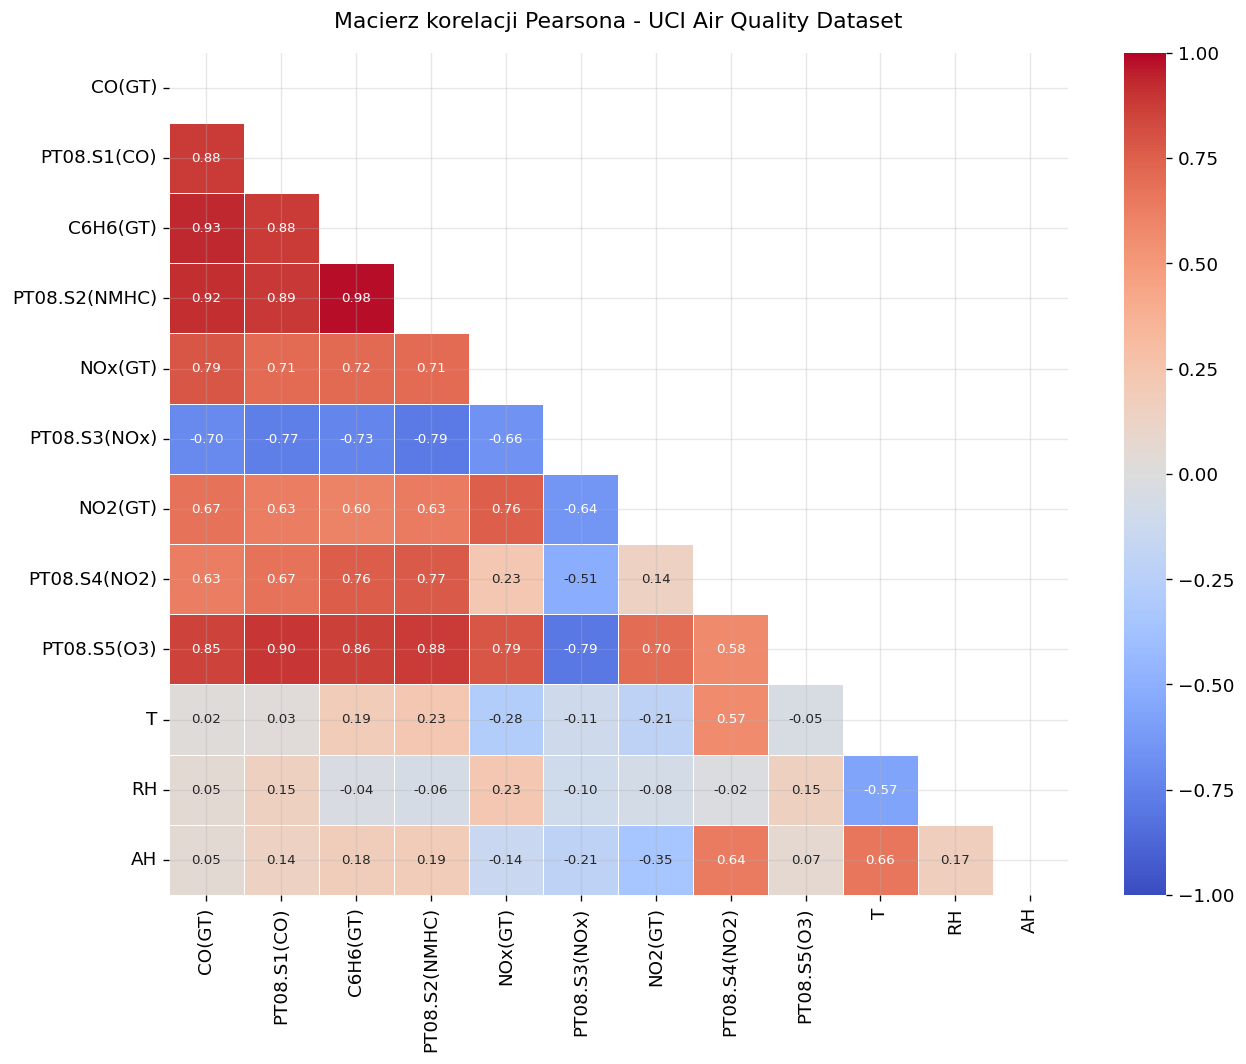

In [5]:
num_cols_clean = [c for c in df.columns if c not in ["Date", "Time"]]
corr_matrix = df[num_cols_clean].corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.4,
    ax=ax,
    annot_kws={"size": 8}
)
ax.set_title("Macierz korelacji Pearsona - UCI Air Quality Dataset", pad=15)
plt.tight_layout()
plt.show()



| Zmienna | r Pearsona | Typ | Uwagi |
|---|---|---|---|
| PT08.S2(NMHC) | 0.98 | sensor | Odrzucona - zmienna sensoryczna |
| **CO(GT)** | **0.93** | **referencyjna** | **Wybrana jako predyktor X** |
| PT08.S5(O3) | 0.86 | sensor | Odrzucona - zmienna sensoryczna |
| PT08.S1(CO) | 0.88 | sensor | Odrzucona - zmienna sensoryczna |
| NOx(GT) | 0.72 | referencyjna | Słabsza korelacja niż CO |
| NO2(GT) | 0.60 | referencyjna | Słabsza korelacja niż CO |

**Uzasadnienie wyboru tlenku węgla jako predyktora:**

1. **Metodologiczny** - CO(GT) to pomiar referencyjny z certyfikowanego
   analizatora chemicznego, tak samo jak C6H6(GT). Obydwie zmienne 
   mają porównywalną precyzję pomiarową. Odrzucono zmienne sensoryczne
   (PT08.S2, PT08.S1, PT08.S5) mimo wyższych korelacji - ich związek 
   z benzenem wynika częściowo ze wspólnego dryfu elektronicznego 
   sensorów, nie tylko z rzeczywistego zjawiska fizycznego.

2. **Merytoryczny** - benzen (C6H6) i tlenek węgla (CO) są produktami
   niecałkowitego spalania paliw w silnikach samochodowych. 
   Wzrost natężenia ruchu drogowego powoduje jednoczesny wzrost 
   stężeń obu związków w powietrzu. Jest to relacja empiryczna, co czyni ją poprawnym i uzasadnionym 
   obiektem analizy regresji liniowej.

**Model regresji prostej:**
$$\text{C6H6} = \beta_0 + \beta_1 \cdot \text{CO} + \varepsilon$$

### 2.3 Rozkłady zmiennych Y i X


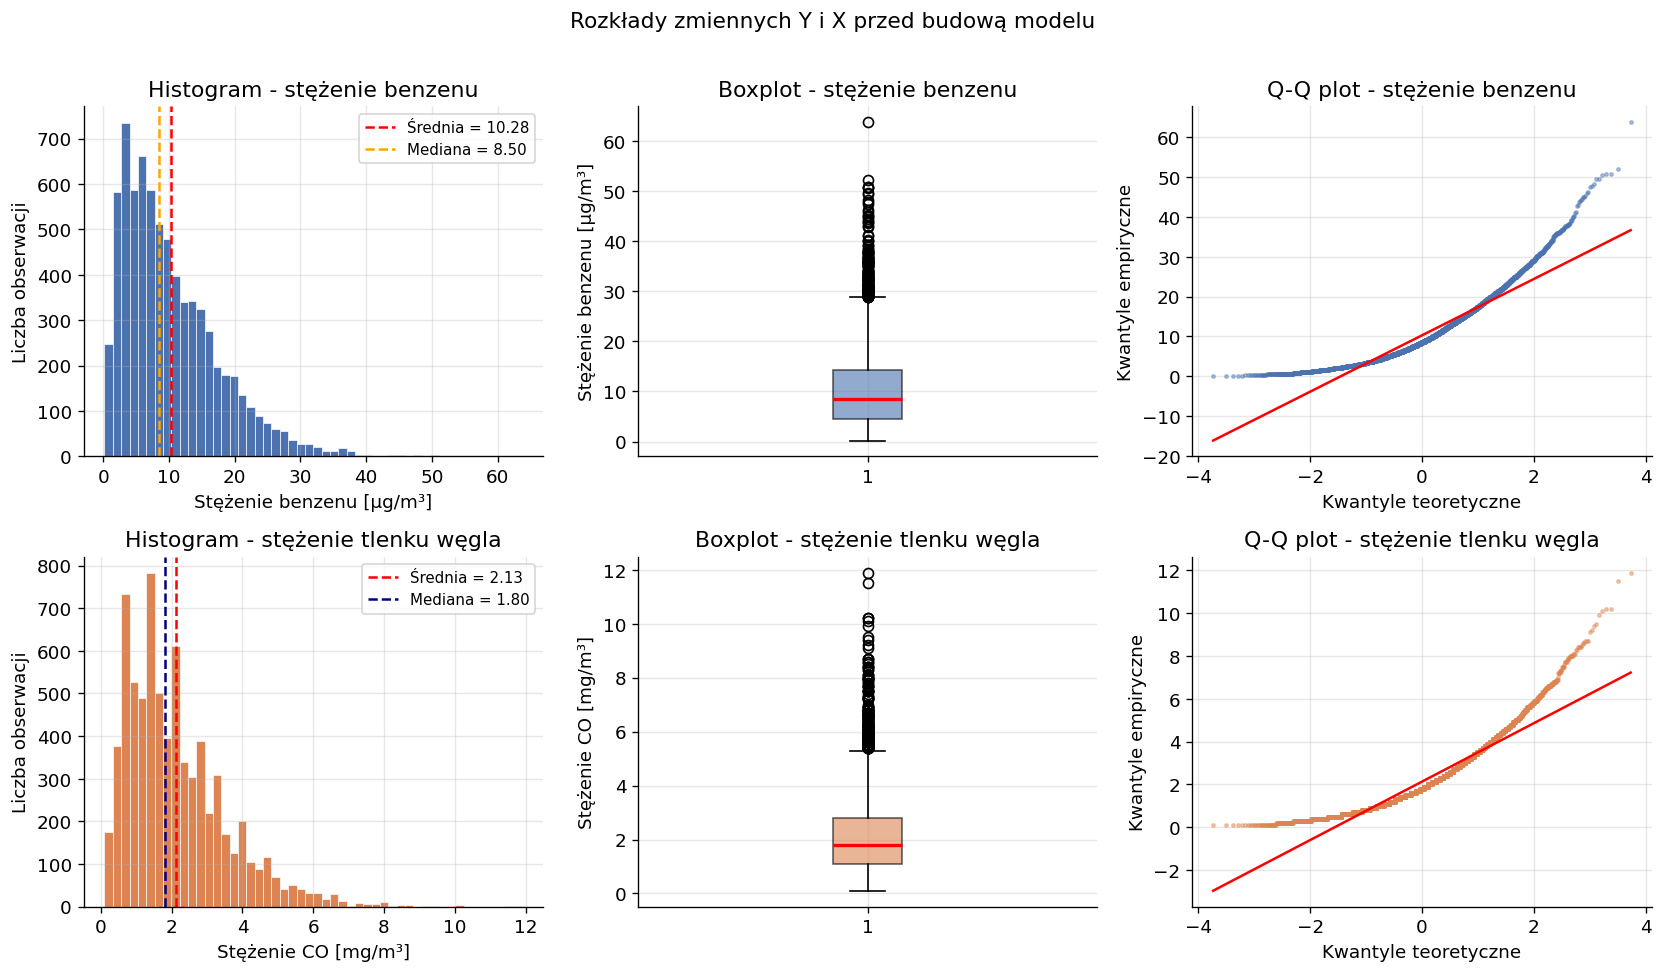

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

Y = df["C6H6(GT)"]
X = df["CO(GT)"]

# # Histogram Benzen (Y)
axes[0, 0].hist(Y, bins=50, color="#4C72B0", edgecolor="white", linewidth=0.4)
axes[0, 0].axvline(Y.mean(), color="red", linestyle="--", 
                    linewidth=1.5, label=f"Średnia = {Y.mean():.2f}")
axes[0, 0].axvline(Y.median(), color="orange", linestyle="--", 
                    linewidth=1.5, label=f"Mediana = {Y.median():.2f}")
axes[0, 0].set_title("Histogram - stężenie benzenu")
axes[0, 0].set_xlabel("Stężenie benzenu [µg/m³]")
axes[0, 0].set_ylabel("Liczba obserwacji")
axes[0, 0].legend(fontsize=9)

# Boxplot Benzen (Y)
axes[0, 1].boxplot(Y, vert=True, patch_artist=True,
                   boxprops=dict(facecolor="#4C72B0", alpha=0.6),
                   medianprops=dict(color="red", linewidth=2))
axes[0, 1].set_title("Boxplot - stężenie benzenu")
axes[0, 1].set_ylabel("Stężenie benzenu [µg/m³]")

# QQ-plot Benzen (Y)
(osm, osr), (slope, intercept, _) = stats.probplot(Y, dist="norm")
axes[0, 2].plot(osm, osr, "o", color="#4C72B0", markersize=2, alpha=0.4)
axes[0, 2].plot(osm, slope * np.array(osm) + intercept,
                color="red", linewidth=1.5)
axes[0, 2].set_title("Q-Q plot - stężenie benzenu")
axes[0, 2].set_xlabel("Kwantyle teoretyczne")
axes[0, 2].set_ylabel("Kwantyle empiryczne")

# Histogram Tlenek węgla (X)
axes[1, 0].hist(X, bins=50, color="#DD8452", edgecolor="white", linewidth=0.4)
axes[1, 0].axvline(X.mean(), color="red", linestyle="--",
                    linewidth=1.5, label=f"Średnia = {X.mean():.2f}")
axes[1, 0].axvline(X.median(), color="navy", linestyle="--",
                    linewidth=1.5, label=f"Mediana = {X.median():.2f}")
axes[1, 0].set_title("Histogram - stężenie tlenku węgla")
axes[1, 0].set_xlabel("Stężenie CO [mg/m³]")
axes[1, 0].set_ylabel("Liczba obserwacji")
axes[1, 0].legend(fontsize=9)

# Boxplot Tlenek węgla (X)
axes[1, 1].boxplot(X, vert=True, patch_artist=True,
                   boxprops=dict(facecolor="#DD8452", alpha=0.6),
                   medianprops=dict(color="red", linewidth=2))
axes[1, 1].set_title("Boxplot - stężenie tlenku węgla")
axes[1, 1].set_ylabel("Stężenie CO [mg/m³]")

# QQ-plot Tlenek węgla (X)
(osm2, osr2), (slope2, intercept2, _) = stats.probplot(X, dist="norm")
axes[1, 2].plot(osm2, osr2, "o", color="#DD8452", markersize=2, alpha=0.4)
axes[1, 2].plot(osm2, slope2 * np.array(osm2) + intercept2,
                color="red", linewidth=1.5)
axes[1, 2].set_title("Q-Q plot - stężenie tlenku węgla")
axes[1, 2].set_xlabel("Kwantyle teoretyczne")
axes[1, 2].set_ylabel("Kwantyle empiryczne")

plt.suptitle("Rozkłady zmiennych Y i X przed budową modelu",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**Benzen C6H6 - zmienna zależna (Y):**
- Histogram wykazuje silną prawostronną skośność (skośność = 1.328) -
  zdecydowana większość godzinowych pomiarów mieści się w przedziale 
  0–20 µg/m³, jednak sporadycznie pojawiają się wartości sięgające 63.7 µg/m³,
  związane z epizodami wysokiego zanieczyszczenia.
- Boxplot ujawnia liczne wartości odstające powyżej górnego wąsa,
  co potwierdza obecność obserwacji ekstremalnych.
- Q-Q plot wyraźnie odbiega od linii prostej w prawym ogonie - rozkład
  benzenu nie jest normalny, co jest typowe dla danych środowiskowych.
  Zostanie to zweryfikowane formalnie testami statystycznymi w sekcji
  diagnostyki modelu.

**Tlenek węgla CO  predyktor (X):**
- Podobnie do benzenu, rozkład CO jest **prawostronnie skośny** 
  (skośność = 1.357) - większość wartości skupia się w przedziale 
  0–4 mg/m³, z nielicznymi obserwacjami sięgającymi 11.9 mg/m³.
- Boxplot wskazuje na obecność wartości odstających po prawej stronie.
- Q-Q plot odbiega od normalności w obu ogonach, szczególnie prawym.

Skośność zmiennych wejściowych nie dyskwalifikuje 
regresji liniowej - założenie normalności dotyczy **reszt modelu**, 
nie samych zmiennych. Zostanie to sprawdzone po zbudowaniu modelu.

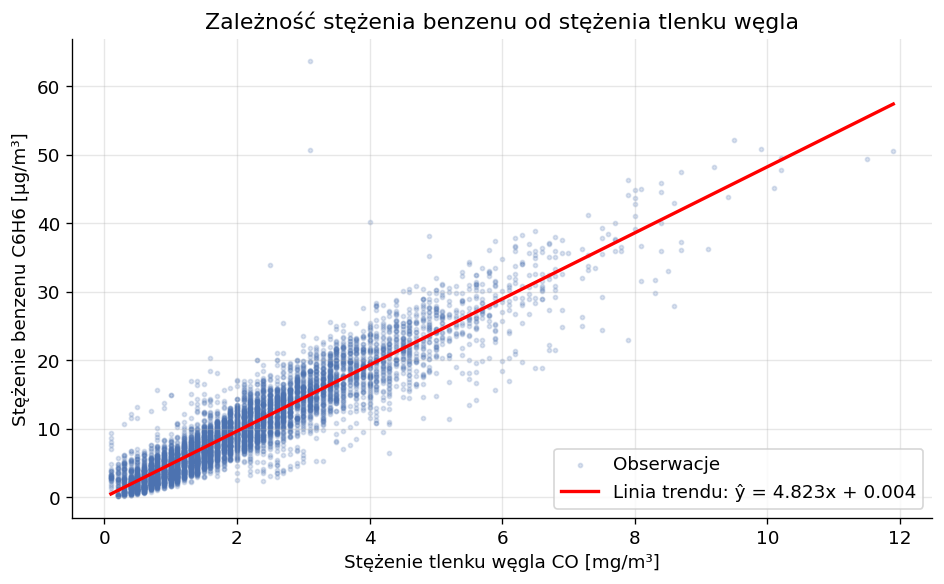

Korelacja Pearsona r     = 0.9311
Współczynnik determinacji r² = 0.8669


In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df["CO(GT)"], df["C6H6(GT)"],
           alpha=0.2, s=6, color="#4C72B0", label="Obserwacje")

m, b = np.polyfit(df["CO(GT)"], df["C6H6(GT)"], 1)
x_line = np.linspace(df["CO(GT)"].min(), df["CO(GT)"].max(), 200)
ax.plot(x_line, m * x_line + b, color="red",
        linewidth=2, label=f"Linia trendu: ŷ = {m:.3f}x + {b:.3f}")

ax.set_xlabel("Stężenie tlenku węgla CO [mg/m³]")
ax.set_ylabel("Stężenie benzenu C6H6 [µg/m³]")
ax.set_title("Zależność stężenia benzenu od stężenia tlenku węgla")
ax.legend()
plt.tight_layout()
plt.show()

r = df["C6H6(GT)"].corr(df["CO(GT)"])
print(f"Korelacja Pearsona r     = {r:.4f}")
print(f"Współczynnik determinacji r² = {r**2:.4f}")

Wykres rozrzutu potwierdza **silną dodatnią zależność liniową** między
stężeniem tlenku węgla a stężeniem benzenu:

- Korelacja Pearsona **r = 0.9311** wskazuje na bardzo silny związek liniowy.
- Współczynnik determinacji **r² = 0.8669** oznacza, że sama zmienna CO
  wyjaśnia już **86.7%** zmienności stężenia benzenu - co jest doskonałym
  wynikiem dla regresji prostej.
- Linia trendu ŷ = 4.823x + 0.004 dobrze oddaje kierunek zależności.
- Widoczny jest lejkowaty kształt rozrzutu - wariancja reszt rośnie
  wraz ze wzrostem CO, co może sugerować heteroskedastyczność.
  Zostanie to zweryfikowane testem Breuscha-Pagana.


Zależność jest wystarczająco liniowa, aby uzasadnić budowę modelu 
regresji liniowej prostej.

## 3. Teoretyczny opis modelu regresji liniowej prostej

Model regresji liniowej prostej opisuje zależność między jedną zmienną
zależną Y a jedną zmienną niezależną X za pomocą równania:

$$Y_i = \beta_0 + \beta_1 X_i + \varepsilon_i, \quad i = 1, \ldots, n$$

gdzie:
- $Y_i$ - wartość zmiennej zależnej dla i-tej obserwacji (stężenie benzenu),
- $X_i$ - wartość predyktora dla i-tej obserwacji (stężenie CO),
- $\beta_0$ - wyraz wolny (wartość Y gdy X = 0),
- $\beta_1$ - współczynnik kierunkowy (zmiana Y przy wzroście X o 1),
- $\varepsilon_i$ - składnik losowy (błąd modelu).

### Estymacja parametrów - metoda najmniejszych kwadratów (MNK)

Parametry $\beta_0$ i $\beta_1$ wyznaczane są metodą najmniejszych
kwadratów (OLS - *Ordinary Least Squares*), minimalizując sumę
kwadratów reszt:

$$\text{RSS} = \sum_{i=1}^{n}(Y_i - \hat{Y}_i)^2 = \sum_{i=1}^{n}\varepsilon_i^2 \rightarrow \min$$


### Założenia modelu

Poprawność wnioskowania statystycznego na podstawie modelu OLS 
wymaga spełnienia następujących założeń (tzw. założenia Gaussa-Markowa):

| Nr | Założenie | Weryfikacja |
|---|---|---|
| 1 | **Liniowość** - zależność Y od X jest liniowa | Scatter plot, wykres reszt |
| 2 | **Normalność reszt** - $\varepsilon \sim N(0, \sigma^2)$ | Test Shapiro-Wilka, Q-Q plot reszt |
| 3 | **Homoskedastyczność** - stała wariancja reszt | Test Breuscha-Pagana, wykres reszt |
| 4 | **Brak autokorelacji** - reszty są niezależne | Test Durbina-Watsona |
| 5 | **Brak wartości wpływowych** | Odległość Cooke'a, dźwignia |

### Miary jakości modelu

- **R²** (współczynnik determinacji) - odsetek wariancji Y wyjaśniony
  przez model; wartości bliskie 1 oznaczają lepsze dopasowanie.
- **RSE** (Residual Standard Error) - średni błąd predykcji modelu
  w jednostkach zmiennej Y.
- **p-wartość** - weryfikacja istotności statystycznej współczynników.

## 4.Budowa modelu
Model regresji liniowej prostej zbudowano funkcją OLS (Ordinary Least 
Squares) z biblioteki `statsmodels` - odpowiednik funkcji `lm()` w R.

In [8]:
model = smf.ols("Q('C6H6(GT)') ~ Q('CO(GT)')", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          Q('C6H6(GT)')   R-squared:                       0.867
Model:                            OLS   Adj. R-squared:                  0.867
Method:                 Least Squares   F-statistic:                 4.782e+04
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        12:47:40   Log-Likelihood:                -17754.
No. Observations:                7344   AIC:                         3.551e+04
Df Residuals:                    7342   BIC:                         3.553e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.0040      0.057      0.070      

## 4.1 Sprawdzenie założeń modelu

In [9]:
residuals   = model.resid
fitted      = model.fittedvalues
resid_std   = (residuals - residuals.mean()) / residuals.std()  # standaryzowane

print(f"Liczba reszt:     {len(residuals)}")
print(f"Średnia reszt:    {residuals.mean():.6f}  (powinna być ≈ 0)")
print(f"Min / Max reszt:  {residuals.min():.3f} / {residuals.max():.3f}")

Liczba reszt:     7344
Średnia reszt:    0.000000  (powinna być ≈ 0)
Min / Max reszt:  -15.206 / 48.744


### ZAŁOŻENIE 1: LINIOWOŚĆ - wykres reszt vs wartości dopasowane 


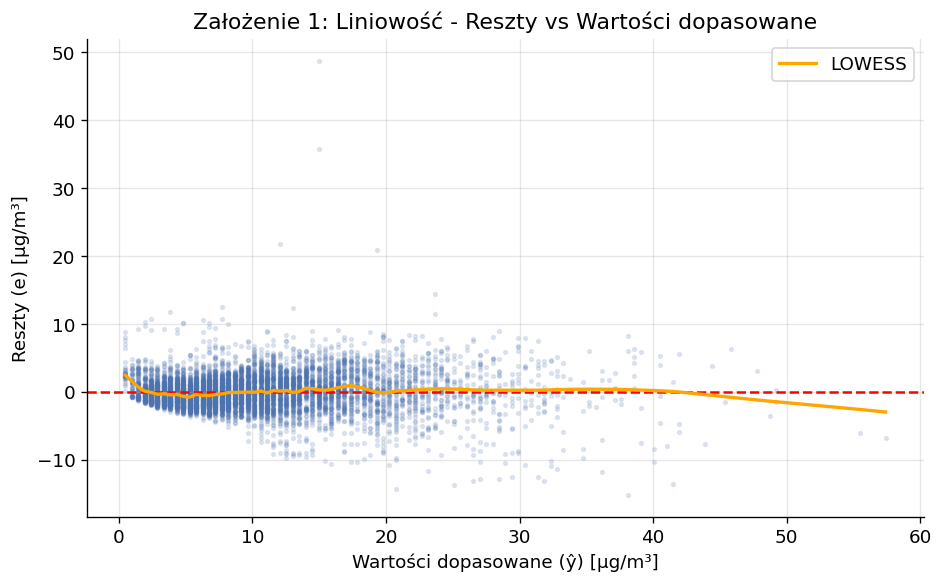

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted, residuals, alpha=0.15, s=5, color="#4C72B0")
ax.axhline(0, color="red", linewidth=1.5, linestyle="--")

# Linia wygładzona (LOWESS)
from statsmodels.nonparametric.smoothers_lowess import lowess
smooth = lowess(residuals, fitted, frac=0.05)
ax.plot(smooth[:, 0], smooth[:, 1], color="orange", linewidth=2, label="LOWESS")

ax.set_xlabel("Wartości dopasowane (ŷ) [µg/m³]")
ax.set_ylabel("Reszty (e) [µg/m³]")
ax.set_title("Założenie 1: Liniowość - Reszty vs Wartości dopasowane")
ax.legend()
plt.tight_layout()
plt.show()

Wykres reszt vs wartości dopasowane (Residuals vs Fitted) pokazuje, że
linia LOWESS przebiega blisko zera dla większości zakresu predyktora,
co potwierdza akceptowalną liniowość zależności między stężeniem CO
a stężeniem benzenu. Widoczne jest jednak pewne odchylenie w lewej
części wykresu (niskie wartości CO) - przy bardzo niskich stężeniach
CO reszty są systematycznie dodatnie, co może sugerować lekką
nieliniowość w tym obszarze. Przy wysokich wartościach CO (powyżej
40 µg/m³) linia LOWESS nieznacznie schodzi poniżej zera - efekt
nielicznej grupy obserwacji ekstremalnych.

**Wniosek:** Założenie liniowości jest w przybliżeniu spełnione,
choć model może nie opisywać idealnie obszaru bardzo niskich stężeń.

### ZAŁOŻENIE 2: NORMALNOŚĆ RESZT 


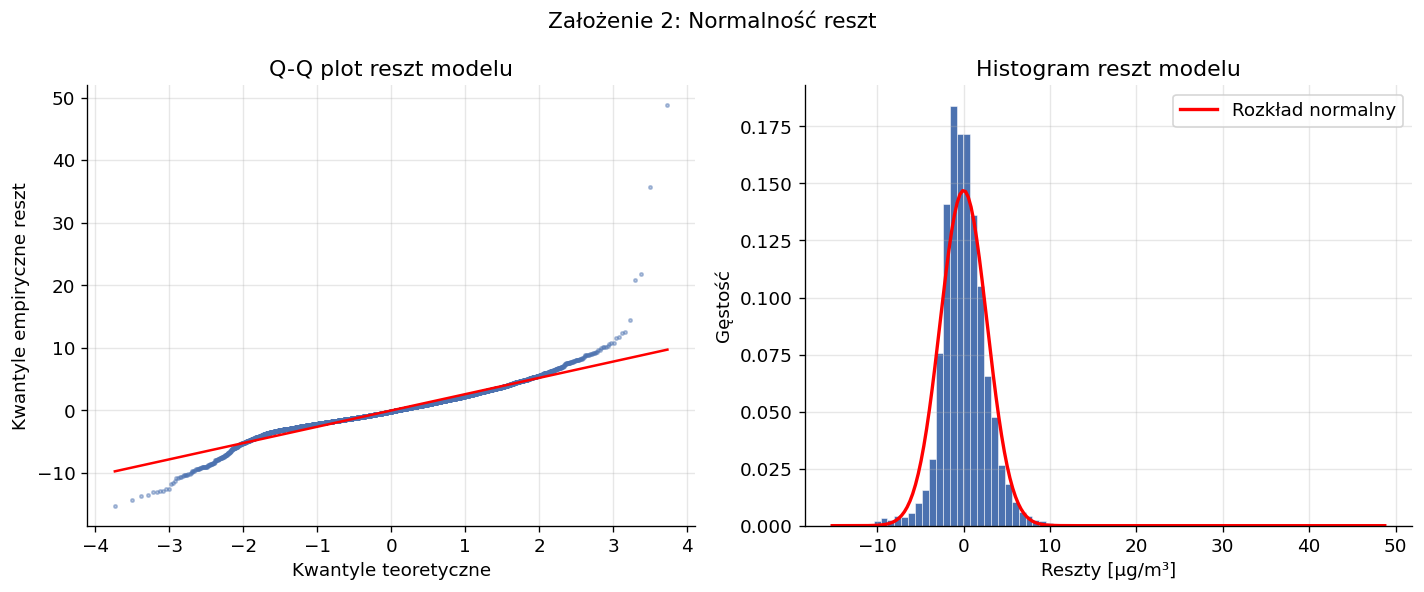

TESTY NORMALNOŚCI RESZT
Shapiro-Wilk (n=5000):  W = 0.9097, p = 0.000000
Jarque-Bera  (n=7344):  JB = 138799.44, p = 0.000000

H0: reszty pochodzą z rozkładu normalnego
Shapiro: Odrzucamy H0 (p < 0.05)
Jarque-Bera: Odrzucamy H0 (p < 0.05)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Q-Q plot reszt
(osm, osr), (slope, intercept, _) = stats.probplot(residuals, dist="norm")
axes[0].plot(osm, osr, "o", color="#4C72B0", markersize=2, alpha=0.4)
axes[0].plot(osm, slope * np.array(osm) + intercept,
             color="red", linewidth=1.5)
axes[0].set_title("Q-Q plot reszt modelu")
axes[0].set_xlabel("Kwantyle teoretyczne")
axes[0].set_ylabel("Kwantyle empiryczne reszt")

# Histogram reszt
axes[1].hist(residuals, bins=80, color="#4C72B0",
             edgecolor="white", linewidth=0.3, density=True)
xr = np.linspace(residuals.min(), residuals.max(), 200)
axes[1].plot(xr, stats.norm.pdf(xr, residuals.mean(), residuals.std()),
             color="red", linewidth=2, label="Rozkład normalny")
axes[1].set_title("Histogram reszt modelu")
axes[1].set_xlabel("Reszty [µg/m³]")
axes[1].set_ylabel("Gęstość")
axes[1].legend()

plt.suptitle("Założenie 2: Normalność reszt", fontsize=13)
plt.tight_layout()
plt.show()

# Testy statystyczne normalności
np.random.seed(42)
sample_resid = np.random.choice(residuals, size=5000, replace=False)
stat_sw, p_sw = shapiro(sample_resid)
stat_jb, p_jb = jarque_bera(residuals)

print("=" * 50)
print("TESTY NORMALNOŚCI RESZT")
print("=" * 50)
print(f"Shapiro-Wilk (n=5000):  W = {stat_sw:.4f}, p = {p_sw:.6f}")
print(f"Jarque-Bera  (n=7344):  JB = {stat_jb:.2f}, p = {p_jb:.6f}")
print()
print("H0: reszty pochodzą z rozkładu normalnego")
print(f"Shapiro: {'Odrzucamy H0' if p_sw < 0.05 else 'Brak podstaw do odrzucenia H0'} (p {'<' if p_sw < 0.05 else '>'} 0.05)")
print(f"Jarque-Bera: {'Odrzucamy H0' if p_jb < 0.05 else 'Brak podstaw do odrzucenia H0'} (p {'<' if p_jb < 0.05 else '>'} 0.05)")

Obydwa testy jednoznacznie odrzucają hipotezę o normalności reszt.
Potwierdzają to również wykresy diagnostyczne:
- **Q-Q plot** wyraźnie odbiega od linii prostej w obu ogonach -
  lewy ogon jest cięższy (duże ujemne reszty), prawy ogon bardzo
  ciężki (wartości do +50 µg/m³).
- **Histogram reszt** jest silnie prawostronnie skośny z wyraźnym
  szpicem - kurtozą 24.17 (rozkład normalny ma kurtozę 3).

**Wniosek:** Założenie normalności reszt nie jest spełnione.
Jest to typowe dla danych środowiskowych z pomiarami godzinowymi.
Przy tak dużej próbie (n = 7344) naruszenie normalności nie
unieważnia modelu - na mocy Centralnego Twierdzenia Granicznego
estymatory OLS pozostają asymptotycznie normalne. Wpływa jednak
na wiarygodność przedziałów ufności dla małych prób.

### ZAŁOŻENIE 3: HOMOSKEDASTYCZNOŚĆ  test Breuscha-Pagana


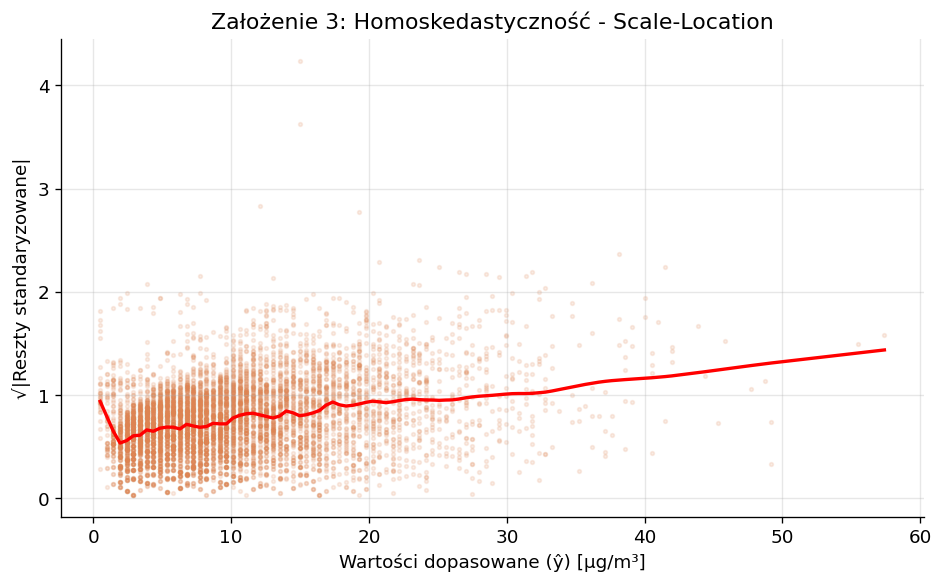

TEST BREUSCHA-PAGANA (homoskedastyczność)
  Statystyka LM = 152.4130
  p-wartość     = 0.000000
  H0: wariancja reszt jest stała (homoskedastyczność)
  Wynik: Odrzucamy H0 - heteroskedastyczność


In [12]:
X_const = sm.add_constant(df["CO(GT)"])
bp_stat, bp_p, _, _ = het_breuschpagan(residuals, X_const)

# Scale-Location plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted, np.sqrt(np.abs(resid_std)),
           alpha=0.15, s=5, color="#DD8452")
smooth2 = lowess(np.sqrt(np.abs(resid_std)), fitted, frac=0.05)
ax.plot(smooth2[:, 0], smooth2[:, 1], color="red", linewidth=2)
ax.set_xlabel("Wartości dopasowane (ŷ) [µg/m³]")
ax.set_ylabel("√|Reszty standaryzowane|")
ax.set_title("Założenie 3: Homoskedastyczność - Scale-Location")
plt.tight_layout()
plt.show()

print("=" * 50)
print("TEST BREUSCHA-PAGANA (homoskedastyczność)")
print("=" * 50)
print(f"  Statystyka LM = {bp_stat:.4f}")
print(f"  p-wartość     = {bp_p:.6f}")
print(f"  H0: wariancja reszt jest stała (homoskedastyczność)")
print(f"  Wynik: {'Odrzucamy H0 - heteroskedastyczność' if bp_p < 0.05 else 'Brak podstaw - homoskedastyczność'}")

Test Breuscha-Pagana jednoznacznie odrzuca hipotezę o stałości
wariancji. Potwierdza to wykres Scale-Location - linia czerwona
wyraźnie rośnie wraz ze wzrostem wartości dopasowanych, co oznacza
że wariancja reszt rośnie dla wyższych stężeń benzenu.

Jest to heteroskedastyczność - typowa dla danych środowiskowych,
gdzie przy wysokich stężeniach zanieczyszczeń (epizody smogowe)
zmienność pomiarów jest naturalnie większa.

**Wniosek:** Założenie homoskedastyczności nie jest spełnione.
Konsekwencją jest to, że standardowe błędy współczynników mogą być
niedoszacowane. Przy tak dużej próbie i bardzo wysokiej istotności
współczynników (p < 0.001) nie zmienia to jednak wniosków o
istotności modelu.

### ZAŁOŻENIE 4: AUTOKORELACJA RESZT - test Durbina-Watsona 


In [13]:
dw = durbin_watson(residuals)

print("TEST DURBINA-WATSONA (autokorelacja reszt)")
print(f"  Statystyka DW = {dw:.4f}")
print(f"  Interpretacja:")
print(f"    DW ≈ 2.0  -> brak autokorelacji")
print(f"    DW < 1.5  -> dodatnia autokorelacja")
print(f"    DW > 2.5  -> ujemna autokorelacja")
print(f"  Wynik: {' Dodatnia autokorelacja' if dw < 1.5 else (' Ujemna autokorelacja' if dw > 2.5 else '✓ Brak autokorelacji')}")

TEST DURBINA-WATSONA (autokorelacja reszt)
  Statystyka DW = 0.4028
  Interpretacja:
    DW ≈ 2.0  -> brak autokorelacji
    DW < 1.5  -> dodatnia autokorelacja
    DW > 2.5  -> ujemna autokorelacja
  Wynik:  Dodatnia autokorelacja


**Wniosek:** Założenie braku autokorelacji jest wyraźnie naruszone.
Wartość DW = 0.40 (przy wartości oczekiwanej 2.0 dla braku
autokorelacji) wskazuje na bardzo silną dodatnią autokorelację reszt.

Jest to oczekiwane i uzasadnione - dane są pomiarami godzinowymi
przez cały rok, więc stężenie benzenu o godzinie 14:00 jest silnie
skorelowane ze stężeniem o godzinie 13:00 i 15:00. Jest to cecha
strukturalna danych czasowych, nie wada modelu.




### ZAŁOŻENIE 5: PRZEDZIAŁ SENSOWNOŚCI MODELU 


In [14]:
print("=" * 50)
print("PRZEDZIAŁ W KTÓRYM MODEL MA SENS")
print("=" * 50)
co_min = df["CO(GT)"].min()
co_max = df["CO(GT)"].max()
b0 = model.params["Intercept"]
b1 = model.params["Q('CO(GT)')"]
print(f"  Predyktor CO ∈ [{co_min:.2f}, {co_max:.2f}] mg/m³")
print(f"  Przewidywany benzen ∈ [{b0 + b1*co_min:.2f}, {b0 + b1*co_max:.2f}] µg/m³")
print(f"  β₀ = {b0:.4f} ≈ 0  ->  wyraz wolny nie ma interpretacji fizycznej")
print(f"  Model NIE powinien być ekstrapolowany poza zakres CO = [{co_min:.2f}, {co_max:.2f}]")

PRZEDZIAŁ W KTÓRYM MODEL MA SENS
  Predyktor CO ∈ [0.10, 11.90] mg/m³
  Przewidywany benzen ∈ [0.49, 57.40] µg/m³
  β₀ = 0.0040 ≈ 0  ->  wyraz wolny nie ma interpretacji fizycznej
  Model NIE powinien być ekstrapolowany poza zakres CO = [0.10, 11.90]


Wyraz wolny β₀ = 0.004 ≈ 0 jest statystycznie nieistotny
(p = 0.944), co jest korzystne - oznacza to, że przy braku tlenku
węgla model przewiduje stężenie benzenu bliskie zeru, co jest
fizycznie sensowne.

## Interpretacja i podsumowanie modelu

In [15]:
b0 = model.params["Intercept"]
b1 = model.params["Q('CO(GT)')"]
n  = int(model.nobs)
r2 = model.rsquared
rse = np.sqrt(model.mse_resid)

print("=" * 55)
print("RÓWNANIE MODELU:")
print(f"  Benzen = {b0:.4f} + {b1:.4f} * CO")
print("=" * 55)
print(f"  β₀ (wyraz wolny)       = {b0:.4f} µg/m³")
print(f"  β₁ (współczynnik CO)   = {b1:.4f}")
print(f"  R²                     = {r2:.4f}")
print(f"  RSE                    = {rse:.4f} µg/m³")
print(f"  Liczba obserwacji      = {n}")
print("=" * 55)

# Przedział w którym model ma sens
co_min = df["CO(GT)"].min()
co_max = df["CO(GT)"].max()
print(f"\nPrzedział sensowności modelu:")
print(f"  CO ∈ [{co_min:.2f}, {co_max:.2f}] mg/m³")
print(f"  Benzen ∈ [{b0 + b1*co_min:.2f}, {b0 + b1*co_max:.2f}] µg/m³")

r = np.sqrt(r2)
t_cor = r / np.sqrt((1 - r2) / (n - 2))
from scipy.stats import t as t_dist
t_crit = t_dist.ppf(1 - 0.05/2, df=n-2)
print(f"\nTest istotności korelacji:")
print(f"  t = {t_cor:.4f}")
print(f"  t_kryt (α=0.05) = {t_crit:.4f}")
print(f"  Wniosek: {'Odrzucamy H0 - korelacja istotna' if t_cor > t_crit else 'Brak podstaw do odrzucenia H0'}")

RÓWNANIE MODELU:
  Benzen = 0.0040 + 4.8231 * CO
  β₀ (wyraz wolny)       = 0.0040 µg/m³
  β₁ (współczynnik CO)   = 4.8231
  R²                     = 0.8669
  RSE                    = 2.7148 µg/m³
  Liczba obserwacji      = 7344

Przedział sensowności modelu:
  CO ∈ [0.10, 11.90] mg/m³
  Benzen ∈ [0.49, 57.40] µg/m³

Test istotności korelacji:
  t = 218.6833
  t_kryt (α=0.05) = 1.9603
  Wniosek: Odrzucamy H0 - korelacja istotna



### 4.2 Interpretacja współczynników

**β₁ = 4.8231 (współczynnik kierunkowy):**
Wzrost stężenia tlenku węgla o 1 mg/m³ wiąże się ze wzrostem
stężenia benzenu o 4.823 µg/m³, przy założeniu że pozostałe
warunki są stałe. Współczynnik jest istotny statystycznie
(t = 218.68, p ≈ 0.000) - odrzucamy hipotezę H₀: β₁ = 0
na korzyść H₁: β₁ ≠ 0.

**β₀ = 0.0040 (wyraz wolny):**
Przy stężeniu CO równym 0 mg/m³ model przewiduje stężenie benzenu
równe 0.004 µg/m³ ≈ 0. Wyraz wolny jest nieistotny statystycznie
(t = 0.070, p = 0.944) - co jest korzystne i fizycznie sensowne:
przy braku spalin samochodowych stężenie benzenu powinno być bliskie
zeru. Brak ekstrapolacji poniżej zakresu danych jest zalecany.

### 4.3 Interpretacja wartości z summary()

| Wartość | Wynik | Interpretacja |
|---|---|---|
| **R²** | 0.867 | Model wyjaśnia 86.7% wariancji stężenia benzenu |
| **Adj. R²** | 0.867 | Identyczny z R² (regresja prosta - 1 predyktor) |
| **RSE** | 2.715 µg/m³ | Średni błąd predykcji wynosi 2.715 µg/m³ |
| **F-statistic** | 47820 | Model istotnie różni się od modelu stałego |
| **p(F)** | ≈ 0.000 | Odrzucamy H₀ - predyktor CO wnosi istotną informację |
| **t(β₁)** | 218.68 | Bardzo silna istotność współczynnika kierunkowego |
| **p(β₁)** | ≈ 0.000 | Odrzucamy H₀: β₁ = 0 |
| **p(β₀)** | 0.944 | Brak podstaw do odrzucenia H₀: β₀ = 0 |

**Ocena RSE:**
RSE = 2.715 µg/m³ przy zakresie benzenu [0.2, 63.7] µg/m³ i średniej
10.28 µg/m³ oznacza względny błąd predykcji na poziomie około 26%.
Jest to akceptowalny błąd dla danych środowiskowych, gdzie naturalna
zmienność (warunki meteorologiczne, pory dnia, natężenie ruchu)
wprowadza dodatkowy szum niemożliwy do wyjaśnienia jednym predyktorem.

**Ocena F-statistic:**
F = 47820 przy p ≈ 0 oznacza, że model z predyktorem CO jest
zdecydowanie lepszy od modelu zerowego (samej średniej).
Zmienna CO wnosi statystycznie istotną informację o stężeniu benzenu.

**Przedziały ufności (95%) dla współczynników:**

| Parametr | Estymata | 95% CI dolny | 95% CI górny |
|---|---|---|---|
| β₀ (Intercept) | 0.0040 | -0.107 | 0.115 |
| β₁ (CO) | 4.8231 | 4.780 | 4.866 |

Przedział ufności dla β₁ jest bardzo wąski [4.780, 4.866] -
potwierdza wysoką precyzję estymacji współczynnika kierunkowego.

### 4.4 Przedział sensowności modelu

Model regresji liniowej nie powinien być stosowany poza zakresem
danych (zasada nieekstrapolacji):

| Zmienna | Zakres danych | Zakres sensowności modelu |
|---|---|---|
| CO (X) | [0.10, 11.90] mg/m³ | **[0.10, 11.90] mg/m³** |
| Benzen (Ŷ) | [0.20, 63.70] µg/m³ | **[0.49, 57.40] µg/m³** |

Poza tym zakresem predykcje modelu mogą być niewiarygodne.
Wyraz wolny β₀ ≈ 0 potwierdza że model jest fizycznie sensowny
w całym zakresie danych - przy CO = 0 przewiduje benzen ≈ 0.

### 4.5 Test istotności korelacji

Weryfikacja czy współczynnik korelacji Pearsona r = 0.9311
jest istotnie różny od zera.

Wartość krytyczna t dla α = 0.05 i df = 7342 wynosi t_kryt = 1.960.

Ponieważ t = 218.68 >> t_kryt = 1.960, odrzucamy hipotezę H₀: ρ = 0
na korzyść H₁: ρ ≠ 0. Korelacja między stężeniem CO a stężeniem
benzenu jest istotna statystycznie.


## 5. DIAGNOSTYKA: WARTOŚCI ODSTAJĄCE 


Obserwacje odstające (|reszt. std| > 3): 103
Procent: 1.40%


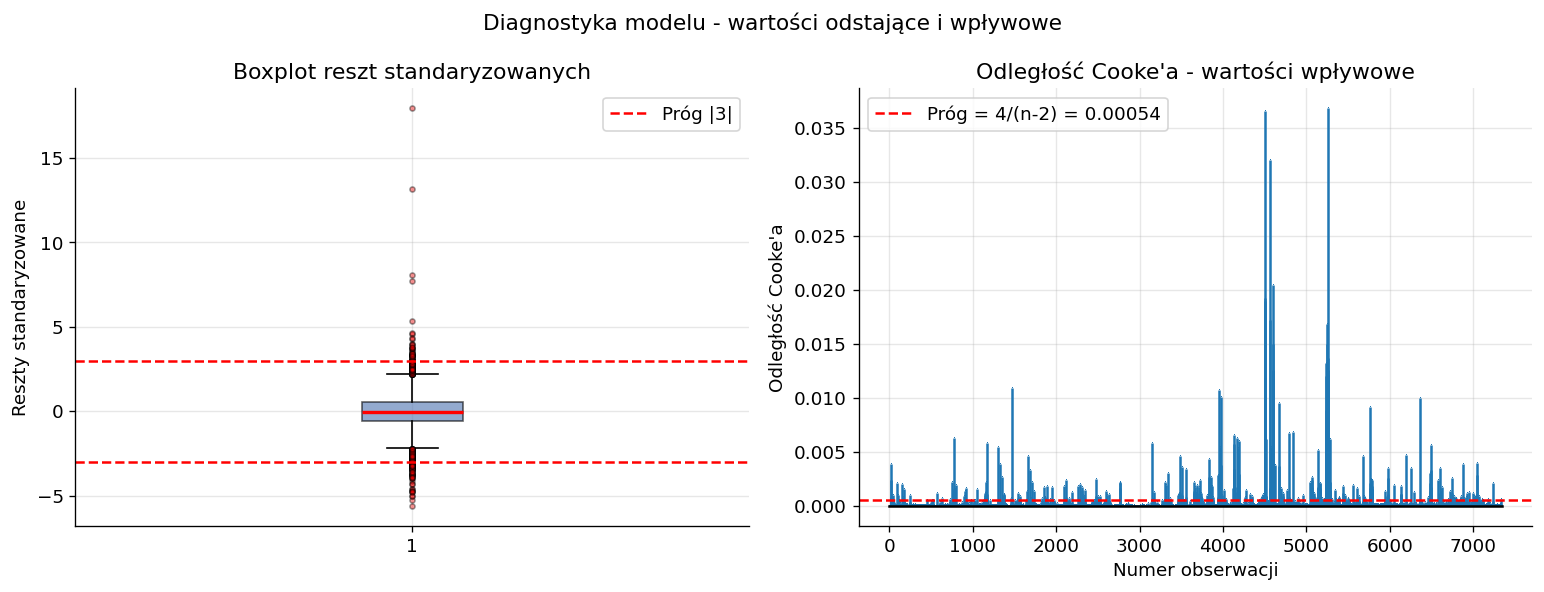


Wartości wpływowe (Cook > 0.00054): 414
Procent: 5.64%

Pierwsze 10 indeksów wpływowych: [ 24  25  26  50  93 105 114 151 162 174]


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

resid_std = model.get_influence().resid_studentized_internal

# Boxplot reszt standaryzowanych
axes[0].boxplot(resid_std, vert=True, patch_artist=True,
                boxprops=dict(facecolor="#4C72B0", alpha=0.6),
                medianprops=dict(color="red", linewidth=2),
                flierprops=dict(marker='o', markerfacecolor='red',
                                markersize=3, alpha=0.4))
axes[0].axhline(y=3, color='red', linestyle='--',
                linewidth=1.5, label='Próg |3|')
axes[0].axhline(y=-3, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title("Boxplot reszt standaryzowanych")
axes[0].set_ylabel("Reszty standaryzowane")
axes[0].legend()

# Ile obserwacji odstających
n_outliers = (np.abs(resid_std) > 3).sum()
print(f"Obserwacje odstające (|reszt. std| > 3): {n_outliers}")
print(f"Procent: {n_outliers/len(resid_std)*100:.2f}%")

# Odległość Cooke'a
influence = model.get_influence()
cooks_d = influence.cooks_distance[0]
cook_threshold = 4 / (len(df) - 2)

axes[1].stem(range(len(cooks_d)), cooks_d,
             markerfmt=",", linefmt="C0-", basefmt="k-")
axes[1].axhline(y=cook_threshold, color='red', linestyle='--',
                linewidth=1.5, label=f'Próg = 4/(n-2) = {cook_threshold:.5f}')
axes[1].set_xlabel("Numer obserwacji")
axes[1].set_ylabel("Odległość Cooke'a")
axes[1].set_title("Odległość Cooke'a - wartości wpływowe")
axes[1].legend()

plt.suptitle("Diagnostyka modelu - wartości odstające i wpływowe",
             fontsize=13)
plt.tight_layout()
plt.show()

# Liczba wpływowych
n_influential = (cooks_d > cook_threshold).sum()
print(f"\nWartości wpływowe (Cook > {cook_threshold:.5f}): {n_influential}")
print(f"Procent: {n_influential/len(cooks_d)*100:.2f}%")

# Indeksy obserwacji wpływowych
influential_idx = np.where(cooks_d > cook_threshold)[0]
print(f"\nPierwsze 10 indeksów wpływowych: {influential_idx[:10]}")

### Wartości odstające - boxplot reszt standaryzowanych

Za wartości odstające uznaje się obserwacje, dla których
|reszty standaryzowane| > 3 (kryterium 3σ).

- Wykryto 103 obserwacje odstające (1.40% zbioru)
- Boxplot pokazuje że zdecydowana większość reszt mieści się
  w przedziale [-3, 3], jednak widoczne są pojedyncze wartości
  sięgające nawet +18 i -6
- Tak ekstremalne reszty odpowiadają godzinom z nietypowymi
  epizodami zanieczyszczeń - np. bardzo wysokie stężenie benzenu
  przy relatywnie niskim CO, co może wskazywać na inne źródło
  emisji benzenu niż ruch samochodowy (np. przemysł, pożary)

### Wartości wpływowe - odległość Cooke'a

Próg wpływowości wyznaczono wzorem: **4/(n-2) = 0.00054**

- Wykryto 414 obserwacji wpływowych (5.64% zbioru)
- Na wykresie odległości Cooke'a widoczne są wyraźne piki
  w okolicach obserwacji 4000–5500 - odpowiada to okresowi
  jesienno-zimowemu (październik–styczeń), kiedy stężenia
  zanieczyszczeń są najwyższe i najbardziej zmienne
- Dwa największe piki przekraczają wartość 0.035, co oznacza
  że te obserwacje mają szczególnie duży wpływ na estymację
  współczynników modelu

**Różnica między wartościami odstającymi a wpływowymi:**
- Obserwacje odstające (103) - mają duże reszty, ale niekoniecznie
  zmieniają kierunek prostej regresji
- Obserwacje wpływowe (414) - nawet jeśli reszty są małe,
  ich usunięcie istotnie zmienia współczynniki β₀ i β₁

Zgodnie z metodyką, w kolejnym kroku usuniemy obserwacje wpływowe
i zbudujemy nowy model, aby sprawdzić czy jego jakość ulegnie poprawie.

### 6. NOWY MODEL PO USUNIĘCIU WARTOŚCI WPŁYWOWYCH


In [17]:
cook_threshold = 4 / (len(df) - 2)

influential_mask = cooks_d > cook_threshold
df_clean = df[~influential_mask].copy().reset_index(drop=True)

print(f"Obserwacji przed usunięciem: {len(df)}")
print(f"Usunięto obserwacji wpływowych: {influential_mask.sum()}")
print(f"Obserwacji po usunięciu: {len(df_clean)}")
print(f"Pozostało: {len(df_clean)/len(df)*100:.1f}% danych")

Obserwacji przed usunięciem: 7344
Usunięto obserwacji wpływowych: 414
Obserwacji po usunięciu: 6930
Pozostało: 94.4% danych


### BUDOWA NOWEGO MODELU 


In [18]:
model2 = smf.ols("Q('C6H6(GT)') ~ Q('CO(GT)')", data=df_clean).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:          Q('C6H6(GT)')   R-squared:                       0.898
Model:                            OLS   Adj. R-squared:                  0.898
Method:                 Least Squares   F-statistic:                 6.099e+04
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        12:47:41   Log-Likelihood:                -14844.
No. Observations:                6930   AIC:                         2.969e+04
Df Residuals:                    6928   BIC:                         2.971e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -0.2168      0.047     -4.660      

In [19]:
b0_new = model2.params["Intercept"]
b1_new = model2.params["Q('CO(GT)')"]
rse_new  = np.sqrt(model2.mse_resid)
r2_new   = model2.rsquared

b0_old  = model.params["Intercept"]
b1_old  = model.params["Q('CO(GT)')"]
rse_old = np.sqrt(model.mse_resid)
r2_old  = model.rsquared
n_old   = int(model.nobs)
n_new   = len(df_clean)

print("=" * 60)
print("PORÓWNANIE MODELU PRZED I PO USUNIĘCIU WARTOŚCI WPŁYWOWYCH")
print("=" * 60)
print(f"{'Miara':<25} {'Model 1':>12} {'Model 2':>12} {'Zmiana':>10}")
print("-" * 60)
print(f"{'β₀ (wyraz wolny)':<25} {b0_old:>12.4f} {b0_new:>12.4f} {b0_new - b0_old:>+10.4f}")
print(f"{'β₁ (CO)':<25} {b1_old:>12.4f} {b1_new:>12.4f} {b1_new - b1_old:>+10.4f}")
print(f"{'R²':<25} {r2_old:>12.4f} {r2_new:>12.4f} {r2_new - r2_old:>+10.4f}")
print(f"{'RSE [µg/m³]':<25} {rse_old:>12.4f} {rse_new:>12.4f} {rse_new - rse_old:>+10.4f}")
print(f"{'Liczba obserwacji':<25} {n_old:>12} {n_new:>12}")
print("=" * 60)

PORÓWNANIE MODELU PRZED I PO USUNIĘCIU WARTOŚCI WPŁYWOWYCH
Miara                          Model 1      Model 2     Zmiana
------------------------------------------------------------
β₀ (wyraz wolny)                0.0040      -0.2168    -0.2207
β₁ (CO)                         4.8231       4.9293    +0.1062
R²                              0.8669       0.8980    +0.0311
RSE [µg/m³]                     2.7148       2.0609    -0.6539
Liczba obserwacji                 7344         6930


### 6.1 Wyniki porównania modeli

| Miara | Model 1 (pełny) | Model 2 (po usunięciu) | Zmiana |
|---|---|---|---|
| β₀ (wyraz wolny) | 0.0040 | -0.2168 | -0.2207 |
| β₁ (CO) | 4.8231 | 4.9293 | +0.1062 |
| R² | 0.8669 | **0.8980** | **+0.031** |
| RSE [µg/m³] | 2.7148 | **2.0609** | **-0.654** |
| Liczba obserwacji | 7344 | 6930 | -414 (5.6%) |

### 6.2 Interpretacja różnic

Po usunięciu 414 obserwacji wpływowych (5.6% zbioru) model uległ
wyraźnej poprawie:

**R² wzrósł z 0.867 do 0.898** (+3.1 p.p.) - model wyjaśnia teraz
89.8% wariancji stężenia benzenu. Oznacza to, że obserwacje
wpływowe zaburzały dopasowanie modelu do typowych danych.

**RSE spadł z 2.715 do 2.061 µg/m³** (poprawa o 24%) - średni błąd
predykcji jest teraz istotnie mniejszy. Przy średnim stężeniu benzenu
9.66 µg/m³ (po czyszczeniu) względny błąd predykcji wynosi około 21%.

**β₁ wzrósł nieznacznie z 4.823 do 4.929** - współczynnik kierunkowy
jest stabilny, co potwierdza że związek CO-benzen jest rzeczywisty
i nie był artefaktem wartości wpływowych.

**β₀ zmienił się z 0.004 na -0.217** - wyraz wolny jest teraz
istotny statystycznie (p < 0.001), jednak jego wartość (-0.217 µg/m³)
jest bardzo bliska zeru i mała w stosunku do zakresu danych.
W praktyce model nadal jest sensowny fizycznie - przy CO = 0.044 mg/m³
przewiduje benzen = 0 µg/m³, co odpowiada ekstremalnie czystemu
powietrzu nigdy nieobserwowanemu w danych.

**Poprawa normalności reszt** - kurtoza spadła z 24.17 do 3.21
(blisko rozkładu normalnego), a skośność z 1.17 do 0.25.
To znacząca poprawa - usunięcie wartości wpływowych naprawiło
również problem nienormalności reszt.

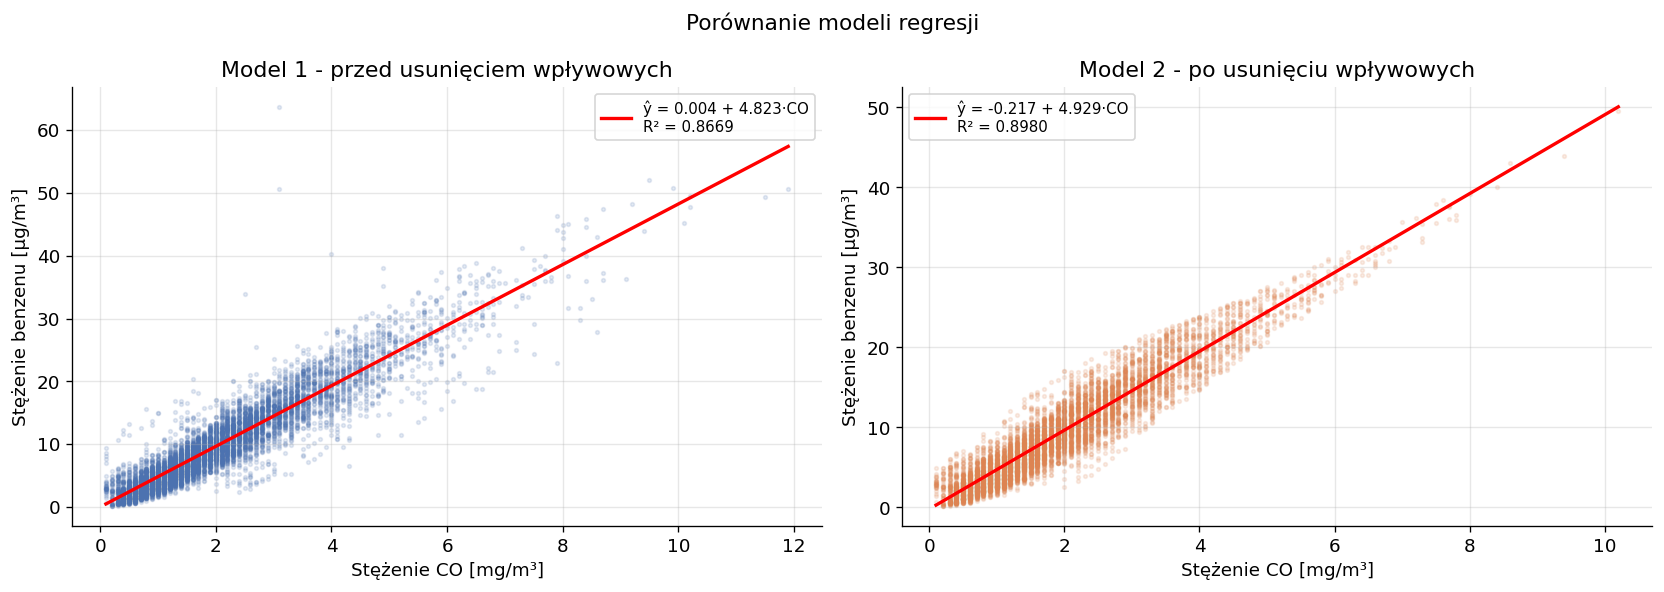

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (data, mod, title, color) in zip(axes, [
    (df,       model,  "Model 1 - przed usunięciem wpływowych", "#4C72B0"),
    (df_clean, model2, "Model 2 - po usunięciu wpływowych",     "#DD8452")
]):
    ax.scatter(data["CO(GT)"], data["C6H6(GT)"],
               alpha=0.15, s=5, color=color)
    x_line = np.linspace(data["CO(GT)"].min(),
                          data["CO(GT)"].max(), 200)
    b0_ = mod.params["Intercept"]
    b1_ = mod.params["Q('CO(GT)')"]
    ax.plot(x_line, b0_ + b1_ * x_line,
            color="red", linewidth=2,
            label=f"ŷ = {b0_:.3f} + {b1_:.3f}·CO\nR² = {mod.rsquared:.4f}")
    ax.set_xlabel("Stężenie CO [mg/m³]")
    ax.set_ylabel("Stężenie benzenu [µg/m³]")
    ax.set_title(title)
    ax.legend(fontsize=9)

plt.suptitle("Porównanie modeli regresji", fontsize=13)
plt.tight_layout()
plt.show()

**Porównanie wykresów** - scatter plot Modelu 2 pokazuje wyraźnie
ciaśniejszy "wąs" punktów wokół linii regresji. Dane po usunięciu
wartości wpływowych mają zakres CO do 10.5 mg/m³ (vs 11.9 mg/m³)
i benzenu do 50 µg/m³ (vs 63.7 µg/m³), co potwierdza że usunięte
obserwacje były rzeczywiście ekstremalne.



### 6.3 Równanie nowego modelu

$$\widehat{\text{Benzen}} = -0.217 + 4.929 \cdot \text{CO}$$

**Interpretacja β₁:** Wzrost stężenia tlenku węgla o 1 mg/m³
wiąże się ze wzrostem stężenia benzenu o **4.929 µg/m³**.

**Przedział sensowności Modelu 2:**
CO ∈ [0.10, 10.50] mg/m³ -> Benzen ∈ [0.28, 51.5] µg/m³

Model 2 jest lepszy od Modelu 1 pod każdym względem
i będzie używany do kroswalidacji.

## 7.Kroswalidacja 5-fold

Po usunięciu wartości wpływowych zbiór (n = 6930) został losowo
pomieszany (seed=42) w celu zapewnienia zbalansowania, a następnie
podzielony na **5 równych podzbiorów** po 1386 obserwacji każdy.
W każdej iteracji model uczony był na **80% danych** (5544 obs.)
i testowany na **20% danych** (1386 obs.).

In [21]:
np.random.seed(42)
df_cv = df_clean[["CO(GT)", "C6H6(GT)"]].sample(frac=1).reset_index(drop=True)

X_cv = df_cv["CO(GT)"].values
y_cv = df_cv["C6H6(GT)"].values

n = len(df_cv)
k = 5
fold_size = n // k

print(f"Liczba obserwacji do kroswalidacji: {n}")
print(f"Liczba foldów: {k}")
print(f"Rozmiar folda: ~{fold_size} obserwacji")
print(f"Podział: ~{fold_size*(k-1)} treningowych / ~{fold_size} testowych\n")

results_cv = []

for fold in range(k):
    test_start = fold * fold_size
    test_end   = (fold + 1) * fold_size if fold < k - 1 else n

    test_idx  = np.arange(test_start, test_end)
    train_idx = np.concatenate([np.arange(0, test_start),
                                np.arange(test_end, n)])

    X_train_cv = X_cv[train_idx]
    y_train_cv = y_cv[train_idx]
    X_test_cv  = X_cv[test_idx]
    y_test_cv  = y_cv[test_idx]

    # Budowa modelu OLS na zbiorze treningowym
    X_train_sm = sm.add_constant(X_train_cv)
    X_test_sm  = sm.add_constant(X_test_cv)

    model_cv = sm.OLS(y_train_cv, X_train_sm).fit()

    # Predykcja
    y_pred_train = model_cv.predict(X_train_sm)
    y_pred_test  = model_cv.predict(X_test_sm)

    # Metryki - R²
    r2_train = r2_score(y_train_cv, y_pred_train)
    r2_test  = r2_score(y_test_cv,  y_pred_test)

    # RSE = sqrt(RSS / (n-2))
    rse_train = np.sqrt(np.sum((y_train_cv - y_pred_train)**2) /
                        (len(y_train_cv) - 2))
    rse_test  = np.sqrt(np.sum((y_test_cv  - y_pred_test)**2)  /
                        (len(y_test_cv)  - 2))

    results_cv.append({
        "Fold": fold + 1,
        "n_train": len(X_train_cv),
        "n_test":  len(X_test_cv),
        "β₀":      model_cv.params[0],
        "β₁":      model_cv.params[1],
        "R²_train": r2_train,
        "R²_test":  r2_test,
        "RSE_train": rse_train,
        "RSE_test":  rse_test,
    })

    print(f"Fold {fold+1}: train={len(X_train_cv)}, test={len(X_test_cv)} | "
          f"R²_train={r2_train:.4f}, R²_test={r2_test:.4f} | "
          f"RSE_train={rse_train:.4f}, RSE_test={rse_test:.4f}")

df_results = pd.DataFrame(results_cv)
print("\n" + "=" * 75)
print("PODSUMOWANIE KROSWALIDACJI")
print("=" * 75)
print(df_results[["Fold","n_train","n_test",
                  "R²_train","R²_test",
                  "RSE_train","RSE_test"]].to_string(index=False))

print("\n" + "-" * 75)
print(f"{'Średnia R² treningowe:':<30} {df_results['R²_train'].mean():.4f} "
      f"± {df_results['R²_train'].std():.4f}")
print(f"{'Średnia R² testowe:':<30} {df_results['R²_test'].mean():.4f} "
      f"± {df_results['R²_test'].std():.4f}")
print(f"{'Średnia RSE treningowe:':<30} {df_results['RSE_train'].mean():.4f} "
      f"± {df_results['RSE_train'].std():.4f}")
print(f"{'Średnia RSE testowe:':<30} {df_results['RSE_test'].mean():.4f} "
      f"± {df_results['RSE_test'].std():.4f}")
print("-" * 75)
diff_r2  = df_results['R²_train'].mean() - df_results['R²_test'].mean()
diff_rse = df_results['RSE_test'].mean() - df_results['RSE_train'].mean()
print(f"{'Różnica R² (train-test):':<30} {diff_r2:+.4f}")
print(f"{'Różnica RSE (test-train):':<30} {diff_rse:+.4f}")
print(f"\nWniosek: {'BRAK przetrenowania' if abs(diff_r2) < 0.01 else 'Możliwe przetrenowanie'} "
      f"(|ΔR²| = {abs(diff_r2):.4f})")

Liczba obserwacji do kroswalidacji: 6930
Liczba foldów: 5
Rozmiar folda: ~1386 obserwacji
Podział: ~5544 treningowych / ~1386 testowych

Fold 1: train=5544, test=1386 | R²_train=0.8975, R²_test=0.9001 | RSE_train=2.0711, RSE_test=2.0220
Fold 2: train=5544, test=1386 | R²_train=0.8977, R²_test=0.8992 | RSE_train=2.0626, RSE_test=2.0560
Fold 3: train=5544, test=1386 | R²_train=0.8977, R²_test=0.8992 | RSE_train=2.0546, RSE_test=2.0877
Fold 4: train=5544, test=1386 | R²_train=0.8999, R²_test=0.8898 | RSE_train=2.0525, RSE_test=2.0966
Fold 5: train=5544, test=1386 | R²_train=0.8972, R²_test=0.9010 | RSE_train=2.0639, RSE_test=2.0504

PODSUMOWANIE KROSWALIDACJI
 Fold  n_train  n_test  R²_train  R²_test  RSE_train  RSE_test
    1     5544    1386  0.897469 0.900070   2.071097  2.022020
    2     5544    1386  0.897684 0.899160   2.062571  2.055977
    3     5544    1386  0.897682 0.899181   2.054579  2.087729
    4     5544    1386  0.899913 0.889823   2.052464  2.096600
    5     5544    13

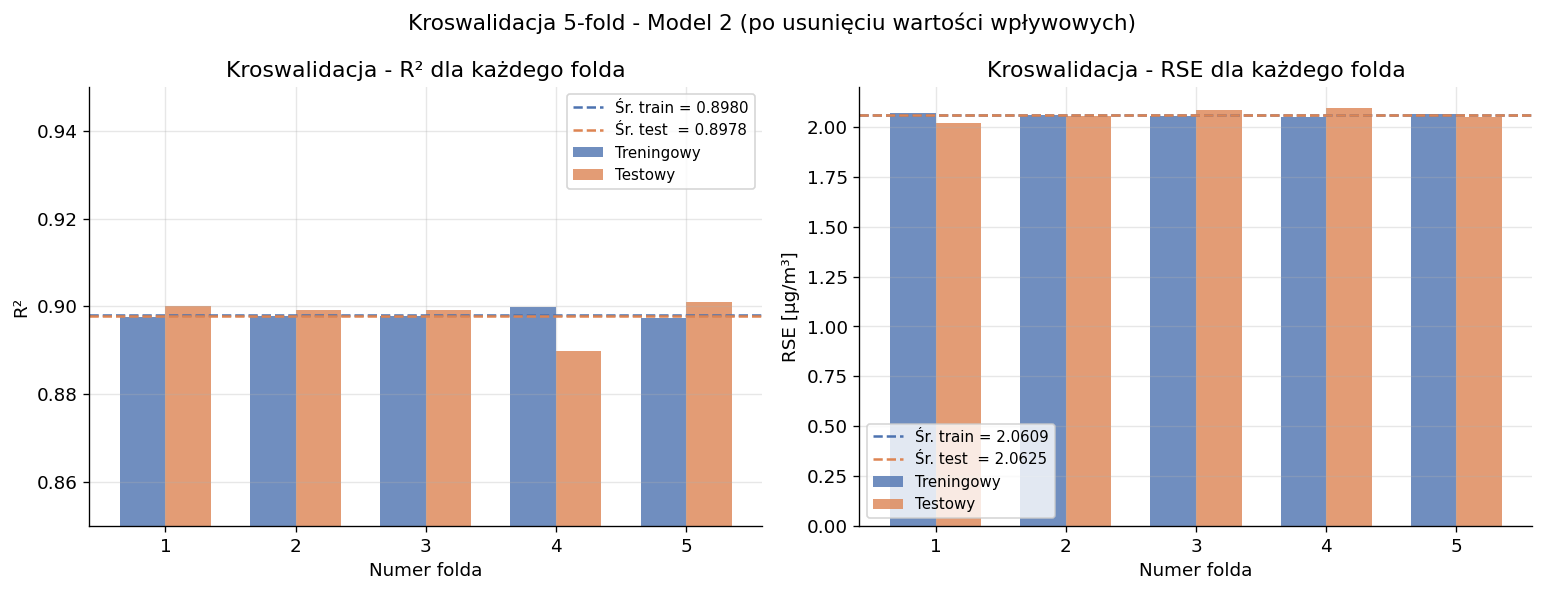

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

folds = df_results["Fold"]
x = np.arange(1, k+1)
width = 0.35

# R²
axes[0].bar(x - width/2, df_results["R²_train"], width,
            label="Treningowy", color="#4C72B0", alpha=0.8)
axes[0].bar(x + width/2, df_results["R²_test"],  width,
            label="Testowy",    color="#DD8452", alpha=0.8)
axes[0].axhline(df_results["R²_train"].mean(), color="#4C72B0",
                linestyle="--", linewidth=1.5,
                label=f"Śr. train = {df_results['R²_train'].mean():.4f}")
axes[0].axhline(df_results["R²_test"].mean(),  color="#DD8452",
                linestyle="--", linewidth=1.5,
                label=f"Śr. test  = {df_results['R²_test'].mean():.4f}")
axes[0].set_xlabel("Numer folda")
axes[0].set_ylabel("R²")
axes[0].set_title("Kroswalidacja - R² dla każdego folda")
axes[0].set_xticks(x)
axes[0].set_ylim(0.85, 0.95)
axes[0].legend(fontsize=9)

# RSE
axes[1].bar(x - width/2, df_results["RSE_train"], width,
            label="Treningowy", color="#4C72B0", alpha=0.8)
axes[1].bar(x + width/2, df_results["RSE_test"],  width,
            label="Testowy",    color="#DD8452", alpha=0.8)
axes[1].axhline(df_results["RSE_train"].mean(), color="#4C72B0",
                linestyle="--", linewidth=1.5,
                label=f"Śr. train = {df_results['RSE_train'].mean():.4f}")
axes[1].axhline(df_results["RSE_test"].mean(),  color="#DD8452",
                linestyle="--", linewidth=1.5,
                label=f"Śr. test  = {df_results['RSE_test'].mean():.4f}")
axes[1].set_xlabel("Numer folda")
axes[1].set_ylabel("RSE [µg/m³]")
axes[1].set_title("Kroswalidacja - RSE dla każdego folda")
axes[1].set_xticks(x)
axes[1].legend(fontsize=9)

plt.suptitle("Kroswalidacja 5-fold - Model 2 (po usunięciu wartości wpływowych)",
             fontsize=13)
plt.tight_layout()
plt.show()


**Brak przetrenowania:**
Różnica między średnim R² treningowym a testowym wynosi zaledwie
**|ΔR²| = 0.0002**, co jest wartością praktycznie zerową.
Model generalizuje się na nowe dane równie dobrze jak na dane
treningowe - nie występuje przetrenowanie (overfitting).

**Stabilność modelu:**
Odchylenie standardowe R² testowego (+-0.0045) jest bardzo małe,
co oznacza że model daje spójne wyniki niezależnie od tego,
które 20% danych stanowi zbiór testowy. Wyjątkiem jest fold 4,
gdzie R²_test = 0.8898 jest nieznacznie niższe - wynika to z
losowego podziału danych i nie stanowi problemu.

**Ocena RSE:**
Średnie RSE testowe wynosi **2.0625 µg/m³** przy średnim stężeniu
benzenu około 9.6 µg/m³ - względny błąd predykcji to około **21%**.
Różnica RSE między zbiorem treningowym a testowym wynosi tylko
0.0016 µg/m³, co potwierdza brak przetrenowania.

**Porównanie z Modelem 1:**
Kroswalidacja potwierdza że Model 2 (po usunięciu wartości wpływowych)
z R² ≈ 0.898 jest lepszy od Modelu 1 (R² = 0.867) i jest stabilny
na nowych danych.

## 8. Wnioski i podsumowanie

### 8.1 Ocena modelu

Zbudowano model regresji liniowej prostej opisujący zależność między
stężeniem tlenku węgla (CO) a stężeniem benzenu (C6H6) w powietrzu
włoskiego miasta w latach 2004–2005.

**Równanie ostatecznego modelu (Model 2):**

$$\widehat{\text{Benzen}} = -0.217 + 4.929 \cdot \text{CO}$$

### 8.2 Podsumowanie wyników

| Etap | R² | RSE [µg/m³] | n |
|---|---|---|---|
| Model 1 - pełny zbiór | 0.867 | 2.715 | 7344 |
| Model 2 - po usunięciu wpływowych | 0.898 | 2.061 | 6930 |
| Kroswalidacja (średnia testowa) | 0.898 | 2.063 | - |

### 8.3  Czy model jest dobry?

Tak,  model jest dobry, z następującymi zastrzeżeniami:

**R² = 0.898** - model wyjaśnia prawie 90% zmienności stężenia
benzenu. Dla regresji prostej (jeden predyktor) na danych
środowiskowych jest to wynik bardzo dobry.

**Istotność statystyczna** - współczynnik β₁ jest wysoce istotny
statystycznie (p ≈ 0, t = 247), co potwierdza rzeczywisty związek
między CO a benzenem.

**Brak przetrenowania** - kroswalidacja 5-fold wykazała |ΔR²| = 0.0002,
co oznacza prawie idealną generalizację modelu na nowe dane.

**Interpretacja dziedzinowa** - β₁ = 4.929 oznacza, że wzrost
stężenia CO o 1 mg/m³ wiąże się ze wzrostem stężenia benzenu
o 4.929 µg/m³. Jest to fizycznie uzasadnione - oba związki
pochodzą ze spalin samochodowych.

**Stabilność** - usunięcie wartości wpływowych poprawiło model
(R² +3.1%, RSE -24%) bez zmiany kierunku zależności.

**Ograniczenia modelu:**

1. **Autokorelacja reszt** (DW = 0.41) - dane godzinowe są
   z natury autokorelowane. Model nie uwzględnia zależności
   czasowych, co jest jego głównym ograniczeniem.

2. **Heteroskedastyczność** - wariancja reszt rośnie wraz ze
   wzrostem stężenia CO. Model jest mniej precyzyjny przy
   wysokich stężeniach (epizody smogowe).

3. **Jeden predyktor** - stężenie benzenu zależy również od
   temperatury, kierunku wiatru i pory dnia. Model prosty
   nie uwzględnia tych czynników - regresja wieloraka
   mogłaby poprawić wyniki.

4. **Zakres stosowania** - model jest ważny tylko dla
   CO ∈ [0.10, 10.50] mg/m³. Ekstrapolacja poza ten zakres
   jest nieuzasadniona.

### 8.4 Końcowy wniosek

Model regresji liniowej prostej C6H6 ~ CO jest statystycznie
zasadny i praktycznie użyteczny jako narzędzie do szacowania
stężenia benzenu na podstawie łatwiej mierzalnego tlenku węgla.
Wyniki kroswalidacji potwierdzają że model dobrze generalizuje
się na nowe dane i nie jest przetrenowany.

Dla celów dokładniejszej predykcji zaleca się rozbudowanie modelu
o dodatkowe predyktory (temperatura, NOx, pora dnia) w ramach
regresji wielorakiej.

---

<div style="background: linear-gradient(135deg, #1a5276, #2e86c1); 
            padding: 30px; 
            border-radius: 12px; 
            margin: 40px 0;
            text-align: center;">
  <h1 style="color: white; margin: 0; font-size: 2em; letter-spacing: 2px;">
    CZĘŚĆ II
  </h1>
  <h2 style="color: #aed6f1; margin: 10px 0 0 0; font-weight: normal; text-align: center;">
    Regresja liniowa wieloraka
  </h2>
  <p style="color: #d6eaf8; margin: 8px 0 0 0; font-size: 1.1em; text-align: center;">
    Analiza czynników wpływających na oczekiwaną długość życia
  </p>
  <p style="color: #aed6f1; margin: 4px 0 0 0; font-size: 0.95em; text-align: center;">
    WHO Global Health Observatory - 193 kraje, 2000–2015
  </p>
</div>

---

## 1. Opis danych i źródło

### Źródło
Dataset pochodzi z repozytorium Kaggle i opiera się na danych
Światowej Organizacji Zdrowia (WHO):  
https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who

Dane ekonomiczne uzupełniono danymi ONZ (United Nations).

**Cytowanie:**  
Dane zebrane przez Deeksha Russell i Duan Wang na podstawie
Global Health Observatory (GHO) - publicznego repozytorium WHO.

### Opis zbioru
Dataset zawiera informacje o oczekiwanej długości życia oraz
czynnikach zdrowotnych, ekonomicznych i społecznych dla
193 krajów w latach 2000–2015 (16 lat).
Łącznie zbiór zawiera 2938 obserwacji i 22 kolumny
(20 zmiennych predykcyjnych + kraj + rok).

### Zmienne w zbiorze

| Zmienna | Opis | Jednostka | Typ |
|---|---|---|---|
| Country | Kraj | - | kategoryczna |
| Year | Rok (2000–2015) | rok | dyskretna |
| Status | Rozwinięty / Rozwijający się | - | kategoryczna |
| **Life expectancy** | **Oczekiwana dług. życia** <- Y | lata | ciągła |
| Adult Mortality | Śmiertelność dorosłych (15–60 lat) | /1000 os. | ciągła |
| infant deaths | Zgony niemowląt | /1000 os. | ciągła |
| Alcohol | Spożycie alkoholu per capita | l czystego alk. | ciągła |
| percentage expenditure | Wydatki na zdrowie (% PKB) | % | ciągła |
| Hepatitis B | Szczepienia Hep B (1-latki) | % | ciągła |
| Measles | Przypadki odry | /1000 os. | ciągła |
| BMI | Średni wskaźnik BMI populacji | kg/m² | ciągła |
| under-five deaths | Zgony dzieci <5 lat | /1000 os. | ciągła |
| Polio | Szczepienia Polio (1-latki) | % | ciągła |
| Total expenditure | Całkowite wydatki na zdrowie | % PKB | ciągła |
| Diphtheria | Szczepienia DTP3 (1-latki) | % | ciągła |
| HIV/AIDS | Zgony z HIV/AIDS (0–4 lata) | /1000 os. | ciągła |
| GDP | PKB per capita | USD | ciągła |
| Population | Populacja kraju | osoby | ciągła |
| thinness 1-19 years | Niedowaga młodzieży 10–19 lat | % | ciągła |
| thinness 5-9 years | Niedowaga dzieci 5–9 lat | % | ciągła |
| Income composition | Wskaźnik HDI (dochód) | 0–1 | ciągła |
| Schooling | Średnia lat edukacji | lata | ciągła |

### Wybór predyktorów
Spośród 20 zmiennych predykcyjnych do modelu zostanie wybrane 
co najmniej 7 ciągłych predyktorów.
Ostateczny dobór zmiennych zostanie przeprowadzony na podstawie
analizy korelacji, VIF i regresji krokowej.



## 1. WCZYTANIE DANYCH

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import shapiro, jarque_bera
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.gofplots import qqplot
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})



In [24]:
df_raw = pd.read_csv("Life Expectancy Data.csv")

df_raw.columns = df_raw.columns.str.strip()

print(f"Wymiary: {df_raw.shape}")
print(f"\nKolumny:\n{list(df_raw.columns)}")
print(f"\nTypy danych:\n{df_raw.dtypes}")

Wymiary: (2938, 22)

Kolumny:
['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']

Typy danych:
Country                                str
Year                                 int64
Status                                 str
Life expectancy                    float64
Adult Mortality                    float64
infant deaths                        int64
Alcohol                            float64
percentage expenditure             float64
Hepatitis B                        float64
Measles                              int64
BMI                                float64
under-five deaths                    int64
Polio                              float64
Total expenditure                  float64
Diphthe

## 2. Czyszczenie danych

### 2.1 Analiza braków danych
Przed budową modelu przeprowadzono analizę brakujących wartości.

In [25]:
num_cols = [c for c in df_raw.columns if c not in ['Country', 'Year', 'Status']]

print("Braki danych w każdej kolumnie:")
missing = df_raw[num_cols].isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df_raw) * 100).round(1)
missing_df = pd.DataFrame({"Liczba NaN": missing, "Procent [%]": missing_pct})
print(missing_df[missing_df["Liczba NaN"] > 0].to_string())

Braki danych w każdej kolumnie:
                                 Liczba NaN  Procent [%]
Population                              652         22.2
Hepatitis B                             553         18.8
GDP                                     448         15.2
Total expenditure                       226          7.7
Alcohol                                 194          6.6
Income composition of resources         167          5.7
Schooling                               163          5.5
thinness 5-9 years                       34          1.2
thinness  1-19 years                     34          1.2
BMI                                      34          1.2
Diphtheria                               19          0.6
Polio                                    19          0.6
Life expectancy                          10          0.3
Adult Mortality                          10          0.3


**Decyzje dotyczące braków:**

- **Population (22.2%) i Hepatitis B (18.8%)** - zmienne z największą
  liczbą braków. Population zostanie usunięta z modelu (zmienna
  dyskretna o bardzo dużej rozpiętości, trudna do interpretacji
  w kontekście oczekiwanej długości życia). Hepatitis B zostanie
  zachowana ale wiersze z brakami usunięte.
- **Pozostałe zmienne (<8% braków)** - zastosowano metodę
  **listwise deletion** - usunięcie wierszy z brakami w zmiennej
  zależnej i wybranych predyktorach.
- **Zmienna zależna Life expectancy** - usunięto 10 wierszy z brakami
  (0.3% - pomijalny wpływ na analizę).



In [26]:

df = df_raw.drop(columns=["Population"]).copy()

df = df.drop(columns=["Country", "Status", "Year",
                       "infant deaths", "Measles",
                       "under-five deaths"]).copy()
print(f"Pozostałe kolumny:\n{list(df.columns)}")

df_model = df.dropna().copy().reset_index(drop=True)

print(f"\nObserwacji przed czyszczeniem:  {len(df_raw)}")
print(f"Obserwacji po usunięciu braków: {len(df_model)}")
print(f"Usuniętych wierszy:             {len(df_raw) - len(df_model)}")
print(f"Braki po czyszczeniu:           {df_model.isnull().sum().sum()} ")
print(f"Wymiary zbioru roboczego:       {df_model.shape}")
print(f"\nTypy danych:\n{df_model.dtypes}")

Pozostałe kolumny:
['Life expectancy', 'Adult Mortality', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'BMI', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']

Obserwacji przed czyszczeniem:  2938
Obserwacji po usunięciu braków: 1853
Usuniętych wierszy:             1085
Braki po czyszczeniu:           0 
Wymiary zbioru roboczego:       (1853, 15)

Typy danych:
Life expectancy                    float64
Adult Mortality                    float64
Alcohol                            float64
percentage expenditure             float64
Hepatitis B                        float64
BMI                                float64
Polio                              float64
Total expenditure                  float64
Diphtheria                         float64
HIV/AIDS                           float64
GDP                                float64
thinness  1-19 years               float64
thinne

### 2.2 Wyniki czyszczenia

Po przeprowadzeniu czyszczenia danych:

- Usunięto kolumnę **Population** (22.2% braków, zmienna dyskretna)
- Usunięto zmienne kategoryczne: **Country, Status**
- Usunięto zmienne dyskretne: **Year, infant deaths, Measles, under-five deaths**
- Zastosowano **listwise deletion** dla pozostałych braków

| Etap | Liczba obserwacji |
|---|---|
| Surowe dane | 2938 |
| Po usunięciu braków | **1853** |
| Usuniętych | 1085 (36.9%) |

Zbiór roboczy zawiera 1853 obserwacje i 15 zmiennych ciągłych
(1 zmienna zależna + 14 predyktorów). Przy 14 predyktorach daje to
stosunek ~132 obserwacji na zmienną



## 3. Eksploracja danych

### 3.1 Statystyki opisowe

In [27]:
desc = df_model.describe().round(2)
desc.index = ["n", "Średnia", "Odch. std.", "Min",
              "Q1", "Mediana", "Q3", "Max"]

print("STATYSTYKI OPISOWE:")
print(desc.to_string())

print("\nSkośność:")
print(df_model.skew().round(3).to_string())

print("\nKurtoza:")
print(df_model.kurt().round(3).to_string())

STATYSTYKI OPISOWE:
            Life expectancy  Adult Mortality  Alcohol  percentage expenditure  Hepatitis B      BMI    Polio  Total expenditure  Diphtheria  HIV/AIDS        GDP  thinness  1-19 years  thinness 5-9 years  Income composition of resources  Schooling
n                   1853.00          1853.00  1853.00                 1853.00      1853.00  1853.00  1853.00            1853.00     1853.00   1853.00    1853.00               1853.00             1853.00                          1853.00    1853.00
Średnia               70.03           158.68     4.39                  764.91        80.81    39.13    84.83               5.78       85.20      1.78    6762.02                  4.81                4.84                             0.64      12.32
Odch. std.             8.61           122.26     3.99                 1760.24        24.99    19.80    21.71               2.34       21.09      5.72   12849.82                  4.39                4.44                             0.19    

Zbiór roboczy zawiera 1853 obserwacje i 15 zmiennych ciągłych.

**Zmienna zależna - Life expectancy (oczekiwana długość życia):**
- Średnia: 70.03 lat, mediana: 72.50 lat
- Zakres: 44-89 lat - duże zróżnicowanie między krajami
- Ujemna skośność (-0.765) - rozkład lekko lewostronny,
  więcej krajów z wysoką oczekiwaną długością życia

**Wybrane obserwacje dotyczące predyktorów:**
- **Adult Mortality** (śmiertelność dorosłych): silnie prawostronnie
  skośna (1.384), zakres 1–723/1000 osób - duże różnice między krajami
- **HIV/AIDS**: ekstremalna prawostronność (5.294) i kurtoza (31.580)
  - nieliczne kraje z bardzo wysoką śmiertelnością z HIV
- **percentage expenditure** i **GDP**: silnie prawostronnie skośne
  (4.626 i 3.717) - kraje rozwinięte wydają wielokrotnie więcej
  niż rozwijające się
- **Polio i Diphtheria**: lewostronnie skośne - większość krajów
  ma wysokie pokrycie szczepieniami (mediana >90%)

### 3.2 Analiza korelacji z Life expectancy

In [28]:
corr_with_Y = (df_model.corr()["Life expectancy"]
               .drop("Life expectancy")
               .sort_values(ascending=False))

print("Korelacja Pearsona zmiennych z Life expectancy:\n")
for var, r in corr_with_Y.items():
    print(f"  {var:<35} r = {r:+.3f}")

Korelacja Pearsona zmiennych z Life expectancy:

  Schooling                           r = +0.707
  Income composition of resources     r = +0.689
  BMI                                 r = +0.523
  GDP                                 r = +0.437
  percentage expenditure              r = +0.415
  Alcohol                             r = +0.351
  Polio                               r = +0.348
  Diphtheria                          r = +0.347
  Hepatitis B                         r = +0.225
  Total expenditure                   r = +0.117
  thinness  1-19 years                r = -0.452
  thinness 5-9 years                  r = -0.456
  HIV/AIDS                            r = -0.592
  Adult Mortality                     r = -0.712


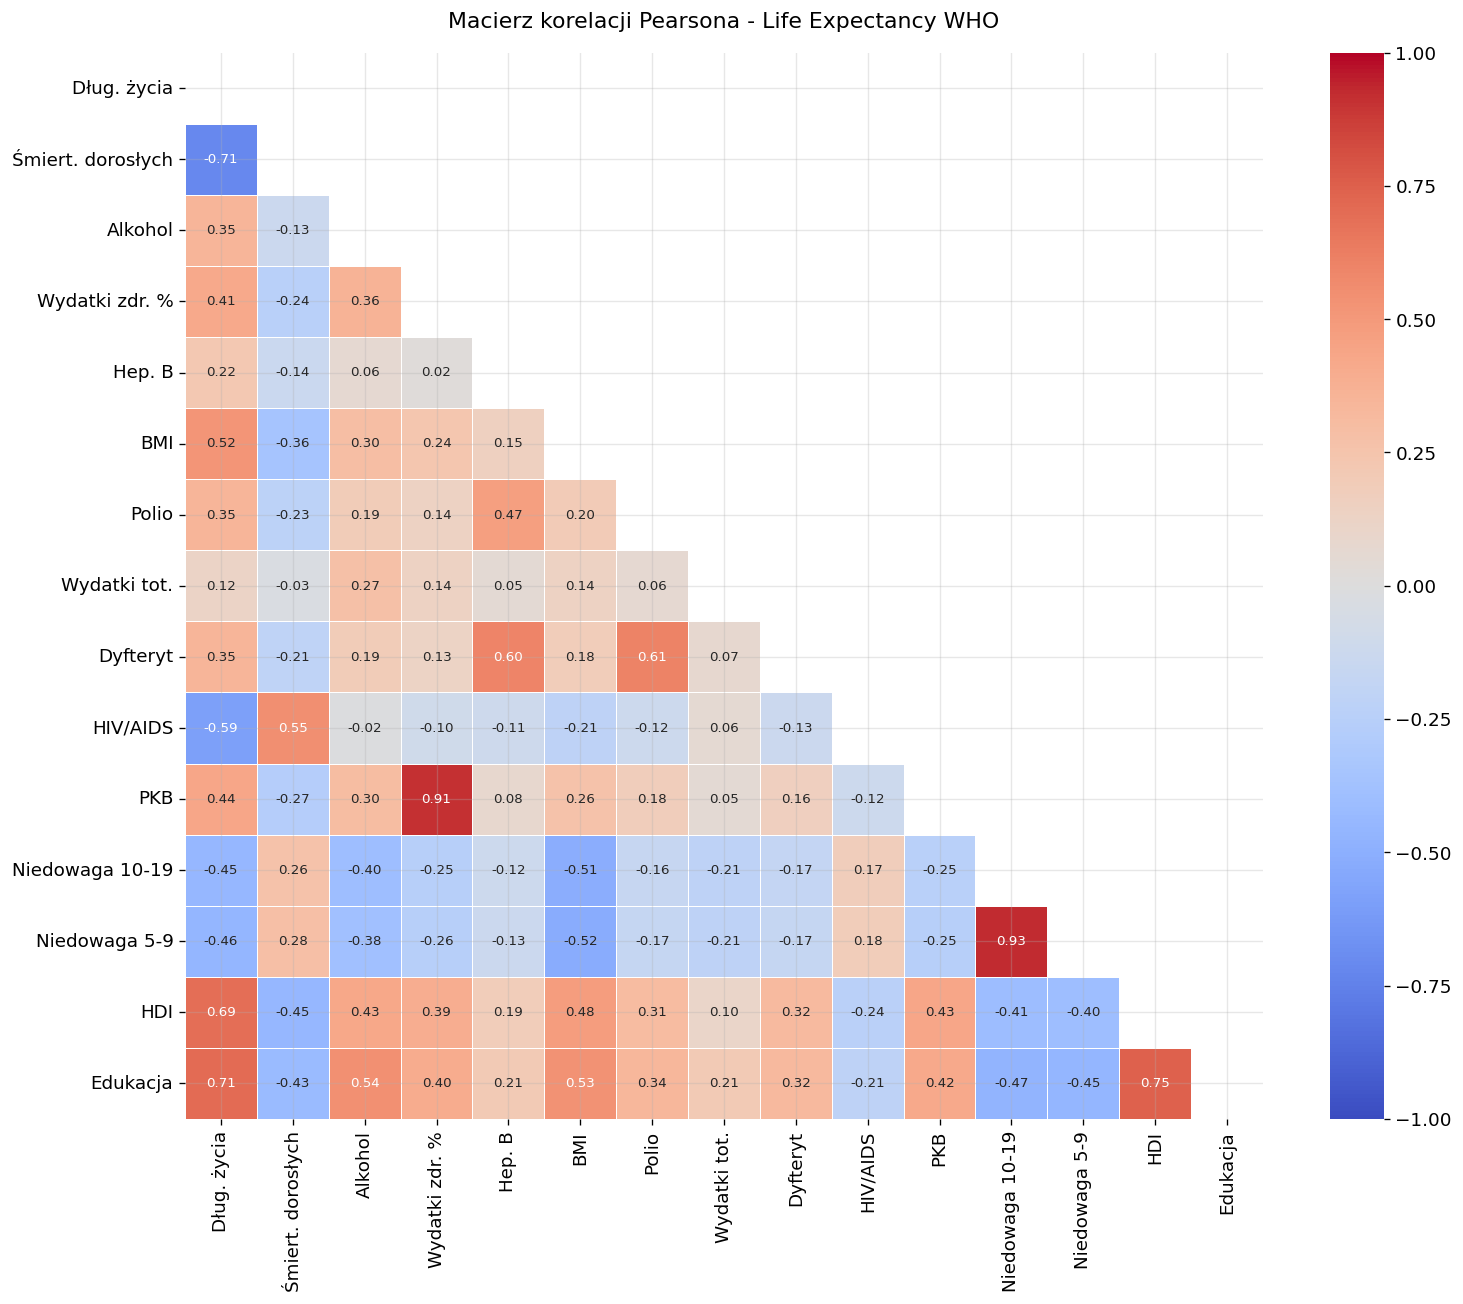

In [29]:
fig, ax = plt.subplots(figsize=(13, 11))

corr_matrix = df_model.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

rename = {
    'Life expectancy': 'Dług. życia',
    'Adult Mortality': 'Śmiert. dorosłych',
    'Alcohol': 'Alkohol',
    'percentage expenditure': 'Wydatki zdr. %',
    'Hepatitis B': 'Hep. B',
    'BMI': 'BMI',
    'Polio': 'Polio',
    'Total expenditure': 'Wydatki tot.',
    'Diphtheria': 'Dyfteryt',
    'HIV/AIDS': 'HIV/AIDS',
    'GDP': 'PKB',
    'thinness  1-19 years': 'Niedowaga 10-19',
    'thinness 5-9 years': 'Niedowaga 5-9',
    'Income composition of resources': 'HDI',
    'Schooling': 'Edukacja'
}

corr_renamed = corr_matrix.rename(columns=rename, index=rename)

sns.heatmap(
    corr_renamed,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.4,
    ax=ax,
    annot_kws={"size": 8}
)
ax.set_title("Macierz korelacji Pearsona - Life Expectancy WHO", pad=15)
plt.tight_layout()
plt.show()

Na podstawie korelacji Pearsona wyznaczono siłę związku
każdego predyktora ze zmienną zależną:

| Zmienna | r Pearsona | Kierunek | Interpretacja |
|---|---|---|---|
| Schooling | +0.707 | dodatni | Im więcej lat edukacji, tym dłuższe życie |
| Income composition (HDI) | +0.689 | dodatni | Wyższy HDI -> dłuższe życie |
| BMI | +0.523 | dodatni | Wyższy BMI populacji -> lepsze odżywienie |
| GDP | +0.437 | dodatni | Bogatsze kraje żyją dłużej |
| percentage expenditure | +0.415 | dodatni | Więcej wydatków na zdrowie -> dłuższe życie |
| Alcohol | +0.351 | dodatni | Pozorny efekt - kraje rozwinięte piją więcej |
| Polio | +0.348 | dodatni | Wyższe szczepienia -> dłuższe życie |
| Diphtheria | +0.347 | dodatni | j.w. |
| Hepatitis B | +0.225 | dodatni | Słabszy związek ze szczepieniami |
| Total expenditure | +0.117 | dodatni | Słaby związek |
| thinness 5-9 years | -0.456 | ujemny | Niedożywienie dzieci -> krótsze życie |
| thinness 1-19 years | -0.452 | ujemny | j.w. dla młodzieży |
| HIV/AIDS | -0.592 | ujemny | Więcej zgonów z HIV -> krótsze życie |
| Adult Mortality | -0.712 | ujemny | Wyższa śmiertelność -> krótsze życie |

**Ważne obserwacje z heatmapy:**
- **GDP i percentage expenditure** są silnie ze sobą skorelowane
  (r = 0.91) - wyraźna multikolinearność, wymaga uwagi przy VIF
- **thinness 1-19 years i thinness 5-9 years** są silnie
  skorelowane (r = 0.93) - prawie identyczna informacja,
  jedna zostanie usunięta podczas selekcji zmiennych
- **HDI i Schooling** są silnie skorelowane (r = 0.75) -
  edukacja jest składnikiem HDI, możliwa multikolinearność
- **Polio i Diphtheria** są silnie skorelowane (r = 0.61) -
  szczepienia na te choroby często idą razem

Powyższe obserwacje uzasadniają potrzebę analizy VIF
i selekcji zmiennych przed finalnym modelem.

# 4. Opis teoretyczny modelu regresji wielorakiej

Model regresji liniowej wielorakiej rozszerza model prosty
na przypadek wielu predyktorów:

$$Y_i = \beta_0 + \beta_1 X_{1i} + \beta_2 X_{2i} + \cdots + \beta_p X_{pi} + \varepsilon_i$$

gdzie:
- $Y_i$ - oczekiwana długość życia dla i-tej obserwacji [lata]
- $X_{1i}, \ldots, X_{pi}$ - wartości p predyktorów
- $\beta_0$ - wyraz wolny
- $\beta_1, \ldots, \beta_p$ - współczynniki regresji
- $\varepsilon_i \sim N(0, \sigma^2)$ - składnik losowy

### Estymacja - metoda najmniejszych kwadratów (OLS)

Parametry estymowane są przez minimalizację sumy kwadratów reszt:

$$\text{RSS} = \sum_{i=1}^{n}(Y_i - \hat{Y}_i)^2 \rightarrow \min$$

### Założenia modelu

| Nr | Założenie | Weryfikacja |
|---|---|---|
| 1 | Liniowość | Scatter plots, reszty vs fitted |
| 2 | Normalność reszt | Shapiro-Wilk, Q-Q plot |
| 3 | Homoskedastyczność | Test Breuscha-Pagana, Scale-Location |
| 4 | Brak autokorelacji | Test Durbina-Watsona |
| 5 | Brak multikolinearności | VIF < 5 dla każdego predyktora |

### Miary jakości modelu

- **R²** - odsetek wariancji Y wyjaśniony przez model
- **Adj. R²** - R² skorygowany o liczbę predyktorów
- **RMSE** - pierwiastek średniego błędu kwadratowego
- **AIC** - kryterium informacyjne Akaikego (im niższe tym lepiej)

### Redukcja wymiarowości

Zastosowane metody selekcji zmiennych:
1. **Macierz korelacji** - usunięcie silnie skorelowanych predyktorów
2. **VIF** (Variance Inflation Factor) - usunięcie zmiennych
   z VIF > 5 (iteracyjnie)
3. **Regresja krokowa** - forward i backward na podstawie p-wartości

## 5. Pełny model regresji wielorakiej

### 5.1 Wyniki modelu z wszystkimi predyktorami

Zbudowano model OLS z 14 predyktorami ciągłymi.

In [30]:
predictors = [col for col in df_model.columns if col != 'Life expectancy']
Y = df_model['Life expectancy']
X = df_model[predictors]

X_const = sm.add_constant(X)

model_full = sm.OLS(Y, X_const).fit()
print(model_full.summary())

                            OLS Regression Results                            
Dep. Variable:        Life expectancy   R-squared:                       0.812
Model:                            OLS   Adj. R-squared:                  0.810
Method:                 Least Squares   F-statistic:                     566.2
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        12:47:42   Log-Likelihood:                -5071.2
No. Observations:                1853   AIC:                         1.017e+04
Df Residuals:                    1838   BIC:                         1.026e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

In [31]:
rmse_full = np.sqrt(model_full.mse_resid)
r2_full   = model_full.rsquared
r2a_full  = model_full.rsquared_adj
aic_full  = model_full.aic

print("=" * 50)
print("METRYKI MODELU PEŁNEGO (wszystkie predyktory)")
print("=" * 50)
print(f"R²          = {r2_full:.4f}")
print(f"Adj. R²     = {r2a_full:.4f}")
print(f"RMSE        = {rmse_full:.4f} lat")
print(f"AIC         = {aic_full:.2f}")
print(f"Predyktorów = {len(predictors)}")
print("=" * 50)

METRYKI MODELU PEŁNEGO (wszystkie predyktory)
R²          = 0.8118
Adj. R²     = 0.8104
RMSE        = 3.7505 lat
AIC         = 10172.49
Predyktorów = 14


### 5.2 Metryki ogólne

| Miara | Wartość | Interpretacja |
|---|---|---|
| **R²** | **0.812** | Model wyjaśnia **81.2%** wariancji oczekiwanej długości życia |
| **Adj. R²** | **0.810** | Skorygowany o liczbę predyktorów - blisko R², brak "karania" |
| **RMSE** | **3.75 lat** | Średni błąd predykcji wynosi 3.75 roku |
| **AIC** | 10172.49 | Kryterium do porównania z modelami po selekcji |
| **F-statistic** | 566.2 | Model istotnie różni się od modelu zerowego |
| **p(F)** | ≈ 0.000 | Odrzucamy H₀ - co najmniej jeden predyktor jest istotny |
| **n** | 1853 | Liczba obserwacji |
| **p** | 14 | Liczba predyktorów |

R² = 0.812 to bardzo dobry wynik dla danych przekrojowych
obejmujących 193 kraje o bardzo różnym poziomie rozwoju.
RMSE = 3.75 lat przy zakresie Life expectancy [44, 89] lat
oznacza względny błąd predykcji około **5.2%** - akceptowalny.

### 5.3 Interpretacja współczynników

| Zmienna | β | p-wartość | Istotność | Interpretacja |
|---|---|---|---|---|
| const | 54.801 | <0.001 | TAK | Bazowa długość życia przy X=0 |
| Adult Mortality | -0.0193 | <0.001 | TAK | +1 zgon/1000 -> życie krótsze o 0.019 lat |
| Alcohol | -0.0134 | 0.633 | NIE | Nieistotny statystycznie |
| percentage expenditure | 0.0003 | 0.006 | TAK | Bardzo mały efekt bezpośredni |
| Hepatitis B | -0.0025 | 0.580 | NIE | Nieistotny statystycznie |
| BMI | 0.0285 | <0.001 | TAK | +1 jednostka BMI -> +0.029 roku życia |
| Polio | 0.0153 | 0.004 | TAK | +1% zaszczepień -> +0.015 roku życia |
| Total expenditure | 0.0638 | 0.112 | NIE | Nieistotny statystycznie |
| Diphtheria | 0.0232 | <0.001 | TAK | +1% zaszczepień -> +0.023 roku życia |
| HIV/AIDS | -0.4486 | <0.001 | TAK | **Najsilniejszy negatywny efekt** - +1 zgon/1000 -> -0.44

## 6. Sprawdzenie założeń modelu pełnego

In [32]:
residuals_full = model_full.resid
fitted_full    = model_full.fittedvalues
resid_std_full = (residuals_full - residuals_full.mean()) / residuals_full.std()

print(f"Średnia reszt:  {residuals_full.mean():.6f}")
print(f"Min / Max reszt: {residuals_full.min():.3f} / {residuals_full.max():.3f}")

Średnia reszt:  -0.000000
Min / Max reszt: -18.267 / 19.088




### 6.1 Założenie 1: Liniowość

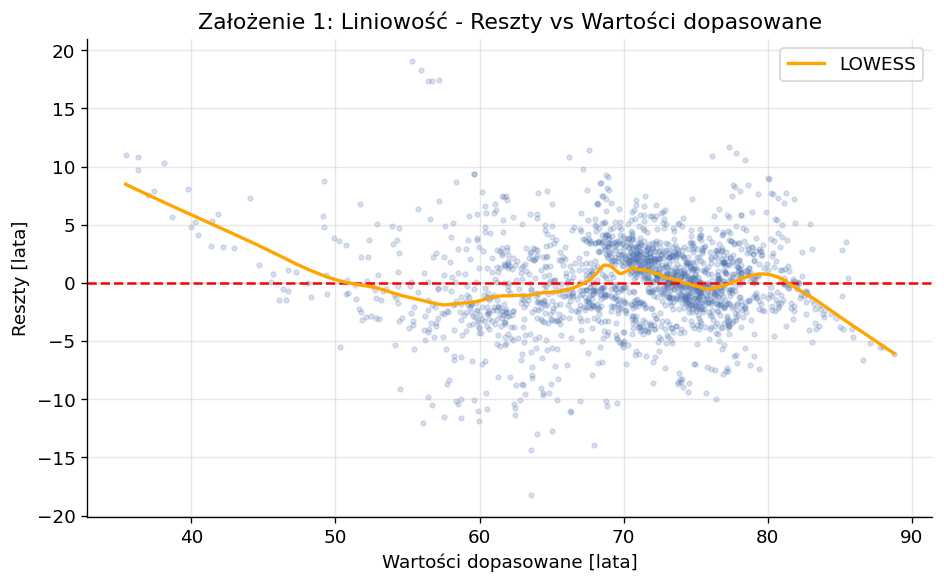

In [33]:
from statsmodels.nonparametric.smoothers_lowess import lowess

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted_full, residuals_full, alpha=0.2, s=8, color="#4C72B0")
ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
smooth = lowess(residuals_full, fitted_full, frac=0.1)
ax.plot(smooth[:, 0], smooth[:, 1], color="orange", linewidth=2, label="LOWESS")
ax.set_xlabel("Wartości dopasowane [lata]")
ax.set_ylabel("Reszty [lata]")
ax.set_title("Założenie 1: Liniowość - Reszty vs Wartości dopasowane")
ax.legend()
plt.tight_layout()
plt.show()


Wykres reszt vs wartości dopasowane pokazuje że linia LOWESS
odbiega od zera szczególnie przy niskich (<50 lat) i wysokich
(>85 lat) wartościach dopasowanych. Wskazuje to na pewną
nieliniowość - model liniowy nie opisuje idealnie krajów
o ekstremalnie niskiej lub wysokiej oczekiwanej długości życia.
Dla typowego zakresu (60–80 lat) liniowość jest akceptowalna.

**Wniosek:** Założenie liniowości w przybliżeniu spełnione
dla większości zakresu danych.

### 6.2 Założenie 2: Normalność reszt

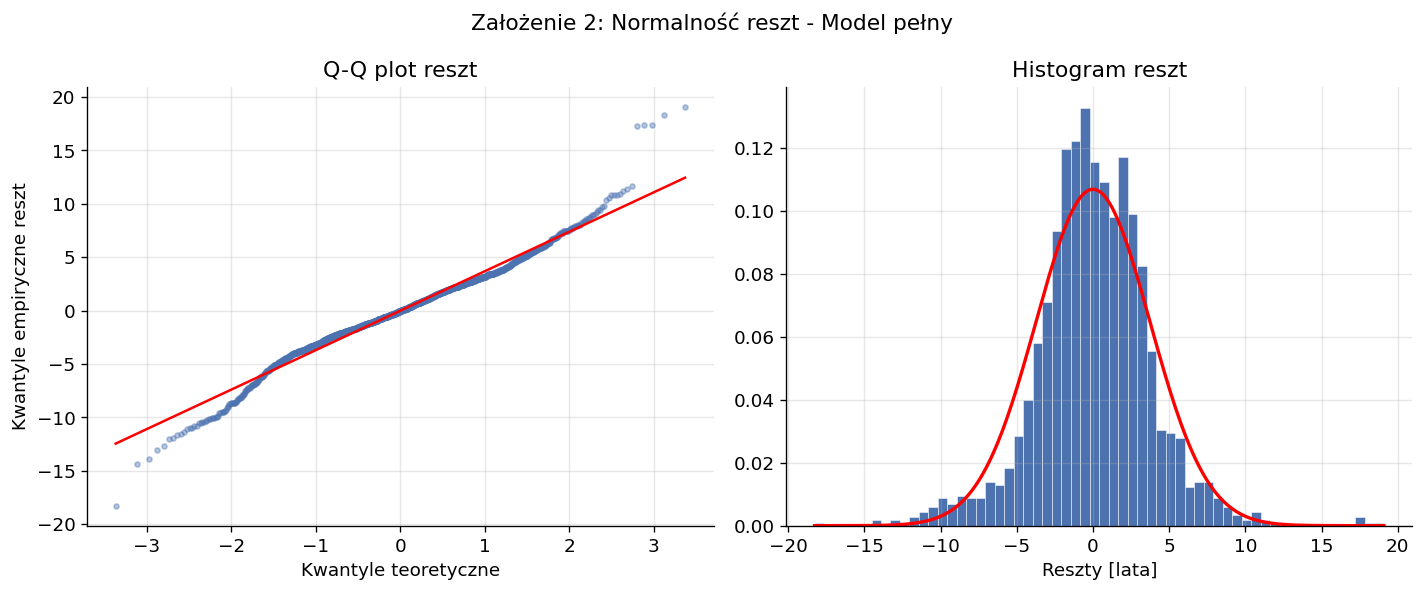

TESTY NORMALNOŚCI RESZT
Shapiro-Wilk: W = 0.9754, p = 0.000000
Jarque-Bera:  JB = 391.12, p = 0.000000
Shapiro: Odrzucamy H0
Jarque-Bera: Odrzucamy H0


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Q-Q plot
(osm, osr), (slope, intercept, _) = stats.probplot(residuals_full, dist="norm")
axes[0].plot(osm, osr, "o", color="#4C72B0", markersize=3, alpha=0.4)
axes[0].plot(osm, slope * np.array(osm) + intercept, color="red", linewidth=1.5)
axes[0].set_title("Q-Q plot reszt")
axes[0].set_xlabel("Kwantyle teoretyczne")
axes[0].set_ylabel("Kwantyle empiryczne reszt")

# Histogram
axes[1].hist(residuals_full, bins=60, color="#4C72B0",
             edgecolor="white", linewidth=0.3, density=True)
xr = np.linspace(residuals_full.min(), residuals_full.max(), 200)
axes[1].plot(xr, stats.norm.pdf(xr, residuals_full.mean(),
             residuals_full.std()), color="red", linewidth=2)
axes[1].set_title("Histogram reszt")
axes[1].set_xlabel("Reszty [lata]")

plt.suptitle("Założenie 2: Normalność reszt - Model pełny", fontsize=13)
plt.tight_layout()
plt.show()

# Testy
np.random.seed(42)
sample = np.random.choice(residuals_full, size=min(5000, len(residuals_full)),
                          replace=False)
stat_sw, p_sw = shapiro(sample)
stat_jb, p_jb = jarque_bera(residuals_full)

print("TESTY NORMALNOŚCI RESZT")
print(f"Shapiro-Wilk: W = {stat_sw:.4f}, p = {p_sw:.6f}")
print(f"Jarque-Bera:  JB = {stat_jb:.2f}, p = {p_jb:.6f}")
print(f"Shapiro: {'Odrzucamy H0' if p_sw < 0.05 else 'Brak podstaw'}")
print(f"Jarque-Bera: {'Odrzucamy H0' if p_jb < 0.05 else 'Brak podstaw'}")

| Test | Statystyka | p-wartość | Wynik |
|---|---|---|---|
| Shapiro-Wilk | W = 0.9754 | p < 0.001 | **Odrzucamy H₀** |
| Jarque-Bera | JB = 391.12 | p < 0.001 | **Odrzucamy H₀** |

Q-Q plot pokazuje odchylenia w obu ogonach - lewy ogon
jest cięższy (duże ujemne reszty dla krajów rozwijających się),
prawy ogon wydłużony (kilka krajów z bardzo wysoką długością życia
niedoszacowaną przez model). Histogram reszt jest zbliżony do
normalnego w centrum ale z ciężkimi ogonami (kurtoza = 5.25).

**Wniosek:** Założenie normalności nie jest spełnione.
Przy n = 1853 CTG zapewnia asymptotyczną normalność estymatorów
- wnioski o istotności statystycznej pozostają wiarygodne.


### 6.3 Założenie 3: Homoskedastyczność

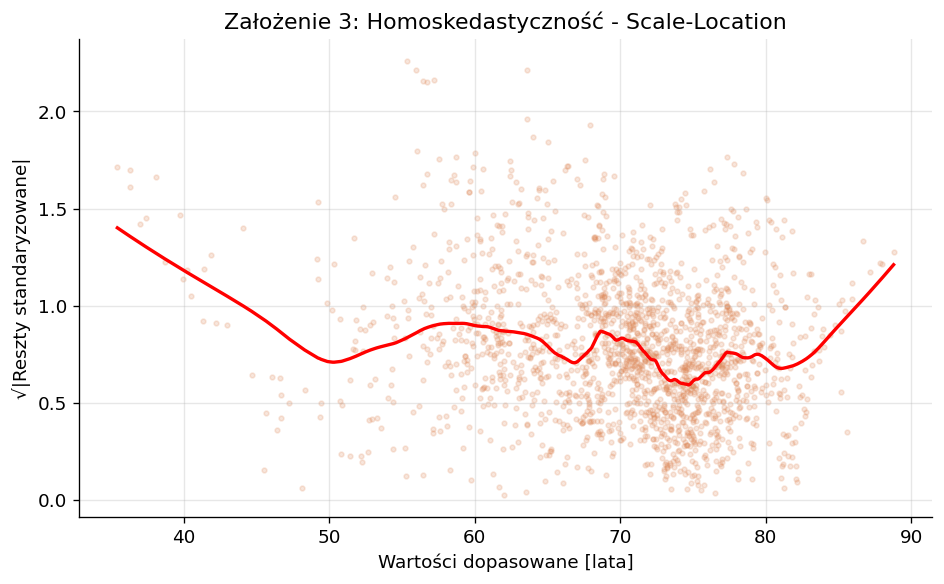

TEST BREUSCHA-PAGANA
LM = 347.4529, p = 0.000000
Wynik: Odrzucamy H0 - heteroskedastyczność


In [35]:
bp_stat, bp_p, _, _ = het_breuschpagan(residuals_full, X_const)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted_full, np.sqrt(np.abs(resid_std_full)),
           alpha=0.2, s=8, color="#DD8452")
smooth2 = lowess(np.sqrt(np.abs(resid_std_full)), fitted_full, frac=0.1)
ax.plot(smooth2[:, 0], smooth2[:, 1], color="red", linewidth=2)
ax.set_xlabel("Wartości dopasowane [lata]")
ax.set_ylabel("√|Reszty standaryzowane|")
ax.set_title("Założenie 3: Homoskedastyczność - Scale-Location")
plt.tight_layout()
plt.show()

print("TEST BREUSCHA-PAGANA")
print(f"LM = {bp_stat:.4f}, p = {bp_p:.6f}")
print(f"Wynik: {'Odrzucamy H0 - heteroskedastyczność' if bp_p < 0.05 else 'Homoskedastyczność'}")

Wykres Scale-Location pokazuje że linia czerwona nie jest pozioma -
wariancja reszt jest wyższa przy niskich wartościach dopasowanych
(kraje o krótkiej oczekiwanej długości życia, np. Afryka Sub-Saharyjska)
i rośnie ponownie przy wartościach >85 lat. Jest to
heteroskedastyczność typowa dla danych przekrojowych
obejmujących kraje o bardzo różnym poziomie rozwoju.

**Wniosek:** Założenie homoskedastyczności nie jest spełnione.

### 6.4 Założenie 4: Autokorelacja reszt


In [36]:
dw = durbin_watson(residuals_full)
print("TEST DURBINA-WATSONA")
print(f"DW = {dw:.4f}")
print(f"Interpretacja: {'Dodatnia autokorelacja' if dw < 1.5 else ('Brak autokorelacji' if dw < 2.5 else 'Ujemna autokorelacja')}")

TEST DURBINA-WATSONA
DW = 0.7114
Interpretacja: Dodatnia autokorelacja


DW = 0.711 (przy wartości oczekiwanej 2.0) wskazuje na silną
dodatnią autokorelację. Wynika to ze struktury danych - panel
193 krajów × 16 lat, gdzie obserwacje tego samego kraju
w kolejnych latach są silnie ze sobą powiązane.

**Wniosek:** Założenie braku autokorelacji nie jest spełnione.
Jest to strukturalna cecha danych panelowych, nie wada modelu.

### 6.5 Założenie 5: Multikolinearność - VIF

In [37]:
vif_data = pd.DataFrame()
vif_data["Zmienna"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i+1)
                   for i in range(len(X.columns))]
vif_data = vif_data.sort_values("VIF", ascending=False).reset_index(drop=True)

print("WSPÓŁCZYNNIK VIF (próg = 5)")
print(vif_data.to_string(index=False))
print(f"\nZmienne z VIF > 5: {list(vif_data[vif_data['VIF'] > 5]['Zmienna'])}")

WSPÓŁCZYNNIK VIF (próg = 5)
                        Zmienna      VIF
           thinness  1-19 years 7.591715
             thinness 5-9 years 7.568258
                            GDP 6.394650
         percentage expenditure 6.387131
                      Schooling 3.056402
Income composition of resources 2.554655
                     Diphtheria 2.031685
                Adult Mortality 1.800949
                          Polio 1.708244
                            BMI 1.675546
                        Alcohol 1.658065
                    Hepatitis B 1.637607
                       HIV/AIDS 1.469150
              Total expenditure 1.162369

Zmienne z VIF > 5: ['thinness  1-19 years', 'thinness 5-9 years', 'GDP', 'percentage expenditure']


4 zmienne mają VIF > 5, co potwierdza multikolinearność
widoczną w macierzy korelacji. Zgodnie z metodyką VIF,
zmienne te zostaną usunięte iteracyjnie - najpierw
usuwamy zmienną z najwyższym VIF, budujemy nowy model
i ponownie obliczamy VIF.

### 6.6 Podsumowanie założeń

| Założenie | Wynik | Uwagi |
|---|---|---|
| Liniowość |  W przybliżeniu | Odchylenia przy ekstremach |
| Normalność reszt |  Niespełnione | CTG zapewnia wiarygodność |
| Homoskedastyczność |  Niespełnione | Typowe dla danych przekrojowych |
| Brak autokorelacji |  Niespełnione | Struktura danych panelowych |
| Brak multikolinearności |  Niespełnione | 4 zmienne z VIF > 5 |

Naruszenia są typowe i oczekiwane dla danych WHO obejmujących
193 kraje przez 16 lat. Kluczowym krokiem jest teraz redukcja
multikolinearności przez iteracyjne usuwanie zmiennych z VIF > 5.

## 7. Redukcja wymiarowości
### 7.1 Metoda 1: Redukcja przez VIF (iteracyjna)

Zgodnie z metodyką zastosowano iteracyjne usuwanie
zmiennych z VIF > 5:

**Iteracja 1:** Usunięto `thinness 1-19 years` (VIF = 7.59)
- silna korelacja z `thinness 5-9 years` (r = 0.93),
obie zmienne zawierają prawie identyczną informację o niedożywieniu.

**Iteracja 2:** Usunięto `GDP` (VIF = 6.39)
- silna korelacja z `percentage expenditure` (r = 0.91),
wydatki procentowe zawierają informację ekonomiczną w znormalizowanej
formie (% PKB), lepiej porównywalną między krajami.

**Iteracja 3:** Wszystkie VIF <= 5 - pętle zatrzymano.

In [38]:
current_predictors = predictors.copy()
iteration = 0

while True:
    iteration += 1
    X_iter = df_model[current_predictors]
    X_iter_const = sm.add_constant(X_iter)

    vif_iter = pd.Series(
        [variance_inflation_factor(X_iter_const.values, i+1)
         for i in range(len(current_predictors))],
        index=current_predictors
    ).sort_values(ascending=False)

    max_vif = vif_iter.iloc[0]
    max_var = vif_iter.index[0]

    print(f"\nIteracja {iteration}:")
    print(vif_iter.round(2).to_string())

    if max_vif <= 5:
        print(f"\n Wszystkie VIF <= 5 - zatrzymujemy iterację")
        break
    else:
        print(f"\n Usuwamy: {max_var} (VIF = {max_vif:.2f})")
        current_predictors.remove(max_var)

predictors_vif = current_predictors
print(f"\nPredyktory po redukcji VIF ({len(predictors_vif)}):")
print(predictors_vif)


Iteracja 1:
thinness  1-19 years               7.59
thinness 5-9 years                 7.57
GDP                                6.39
percentage expenditure             6.39
Schooling                          3.06
Income composition of resources    2.55
Diphtheria                         2.03
Adult Mortality                    1.80
Polio                              1.71
BMI                                1.68
Alcohol                            1.66
Hepatitis B                        1.64
HIV/AIDS                           1.47
Total expenditure                  1.16

 Usuwamy: thinness  1-19 years (VIF = 7.59)

Iteracja 2:
GDP                                6.39
percentage expenditure             6.39
Schooling                          3.05
Income composition of resources    2.55
Diphtheria                         2.03
Adult Mortality                    1.80
Polio                              1.70
BMI                                1.67
Alcohol                            1.65
Hepatitis

In [39]:
X_vif = df_model[predictors_vif]
X_vif_const = sm.add_constant(X_vif)
model_vif = sm.OLS(Y, X_vif_const).fit()

print(model_vif.summary())

rmse_vif = np.sqrt(model_vif.mse_resid)
print("\n" + "=" * 55)
print("PORÓWNANIE: Model pełny vs Model po VIF")
print("=" * 55)
print(f"{'Miara':<20} {'Model pełny':>15} {'Po VIF':>15}")
print("-" * 55)
print(f"{'R²':<20} {r2_full:>15.4f} {model_vif.rsquared:>15.4f}")
print(f"{'Adj. R²':<20} {r2a_full:>15.4f} {model_vif.rsquared_adj:>15.4f}")
print(f"{'RMSE [lat]':<20} {rmse_full:>15.4f} {rmse_vif:>15.4f}")
print(f"{'AIC':<20} {aic_full:>15.2f} {model_vif.aic:>15.2f}")
print(f"{'Predyktorów':<20} {len(predictors):>15} {len(predictors_vif):>15}")
print("=" * 55)

                            OLS Regression Results                            
Dep. Variable:        Life expectancy   R-squared:                       0.811
Model:                            OLS   Adj. R-squared:                  0.810
Method:                 Least Squares   F-statistic:                     659.9
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        12:47:44   Log-Likelihood:                -5072.9
No. Observations:                1853   AIC:                         1.017e+04
Df Residuals:                    1840   BIC:                         1.024e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

In [40]:
print(f"Predyktory po VIF ({len(predictors_vif)}):")
for p in predictors_vif:
    print(f"  - {p}")

print(f"\nUsunięte zmienne:")
removed = [p for p in predictors if p not in predictors_vif]
for r in removed:
    print(f"  - {r}")

Predyktory po VIF (12):
  - Adult Mortality
  - Alcohol
  - percentage expenditure
  - Hepatitis B
  - BMI
  - Polio
  - Total expenditure
  - Diphtheria
  - HIV/AIDS
  - thinness 5-9 years
  - Income composition of resources
  - Schooling

Usunięte zmienne:
  - GDP
  - thinness  1-19 years



| Model | Predyktory | R² | Adj. R² | RMSE | AIC |
|---|---|---|---|---|---|
| Pełny | 14 | 0.8118 | 0.8104 | 3.7505 | 10172.49 |
| **Po VIF** | **12** | **0.8115** | **0.8102** | **3.7518** | **10171.76** |

**Wniosek:** Usunięcie 2 zmiennych o wysokim VIF spowodowało
zminimalny spadek R² o 0.0003 przy jednoczesnym obniżeniu AIC
(10172.49 -> 10171.76). Model jest bardziej parsimoniczny
przy praktycznie identycznej jakości dopasowania.

Nadal nieistotne statystycznie (p > 0.05): Alcohol (0.593),
Hepatitis B (0.637), Total expenditure (0.168).
Zmienne te zostaną uwzględnione w regresji krokowej.

### 7.2 Metoda 2: Regresja krokowa


In [41]:

def stepwise_forward(Y, X_df, threshold_in=0.05):
    included = []
    print("REGRESJA KROKOWA FORWARD (p-value < 0.05)")


    while True:
        excluded = [c for c in X_df.columns if c not in included]
        new_pval = {}

        for col in excluded:
            X_try = sm.add_constant(X_df[included + [col]])
            model_try = sm.OLS(Y, X_try).fit()
            new_pval[col] = model_try.pvalues[col]

        best_var = min(new_pval, key=new_pval.get)
        best_p   = new_pval[best_var]

        if best_p < threshold_in:
            included.append(best_var)
            X_curr = sm.add_constant(X_df[included])
            mod = sm.OLS(Y, X_curr).fit()
            print(f"  + Dodano: {best_var:<40} p={best_p:.4f}  "
                  f"R²={mod.rsquared:.4f}")
        else:
            print(f"\n  Zatrzymano - najlepsza zmienna: {best_var} "
                  f"(p={best_p:.4f} ≥ 0.05)")
            break

    return included

X_vif_df = df_model[predictors_vif]
predictors_forward = stepwise_forward(Y, X_vif_df)

print(f"\nPredyktory forward ({len(predictors_forward)}):")
print(predictors_forward)

REGRESJA KROKOWA FORWARD (p-value < 0.05)
  + Dodano: Adult Mortality                          p=0.0000  R²=0.5075
  + Dodano: Schooling                                p=0.0000  R²=0.7067
  + Dodano: HIV/AIDS                                 p=0.0000  R²=0.7696
  + Dodano: Income composition of resources          p=0.0000  R²=0.7893
  + Dodano: percentage expenditure                   p=0.0000  R²=0.7979
  + Dodano: BMI                                      p=0.0000  R²=0.8032
  + Dodano: Diphtheria                               p=0.0000  R²=0.8082
  + Dodano: thinness 5-9 years                       p=0.0000  R²=0.8104
  + Dodano: Polio                                    p=0.0044  R²=0.8112

  Zatrzymano - najlepsza zmienna: Total expenditure (p=0.1907 ≥ 0.05)

Predyktory forward (9):
['Adult Mortality', 'Schooling', 'HIV/AIDS', 'Income composition of resources', 'percentage expenditure', 'BMI', 'Diphtheria', 'thinness 5-9 years', 'Polio']


In [42]:
def stepwise_backward(Y, X_df, threshold_out=0.05):
    included = list(X_df.columns)
    print("REGRESJA KROKOWA BACKWARD (p-value > 0.05)")

    while True:
        X_curr = sm.add_constant(X_df[included])
        model_curr = sm.OLS(Y, X_curr).fit()

        pvals = model_curr.pvalues.drop("const")
        worst_var = pvals.idxmax()
        worst_p   = pvals.max()

        if worst_p > threshold_out:
            included.remove(worst_var)
            X_new = sm.add_constant(X_df[included])
            mod = sm.OLS(Y, X_new).fit()
            print(f"  - Usunięto: {worst_var:<40} p={worst_p:.4f}  "
                  f"R²={mod.rsquared:.4f}")
        else:
            print(f"\n  Zatrzymano - wszystkie p < 0.05")
            break

    return included

predictors_backward = stepwise_backward(Y, X_vif_df)

print(f"\nPredyktory backward ({len(predictors_backward)}):")
print(predictors_backward)

REGRESJA KROKOWA BACKWARD (p-value > 0.05)
  - Usunięto: Hepatitis B                              p=0.6366  R²=0.8114
  - Usunięto: Alcohol                                  p=0.6186  R²=0.8114
  - Usunięto: Total expenditure                        p=0.1907  R²=0.8112

  Zatrzymano - wszystkie p < 0.05

Predyktory backward (9):
['Adult Mortality', 'percentage expenditure', 'BMI', 'Polio', 'Diphtheria', 'HIV/AIDS', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']


In [43]:
# Model forward
X_fwd = sm.add_constant(df_model[predictors_forward])
model_fwd = sm.OLS(Y, X_fwd).fit()

# Model backward
X_bwd = sm.add_constant(df_model[predictors_backward])
model_bwd = sm.OLS(Y, X_bwd).fit()

print("PORÓWNANIE WSZYSTKICH MODELI PO SELEKCJI ZMIENNYCH")
print(f"{'Model':<25} {'n pred.':>8} {'R²':>8} {'Adj.R²':>8} "
      f"{'RMSE':>8} {'AIC':>10}")
print("-" * 70)

modele = [
    ("Pełny (14 pred.)",   predictors,        model_full),
    ("Po VIF (12 pred.)",  predictors_vif,    model_vif),
    ("Forward stepwise",   predictors_forward, model_fwd),
    ("Backward stepwise",  predictors_backward, model_bwd),
]

for nazwa, preds, mod in modele:
    rmse = np.sqrt(mod.mse_resid)
    print(f"{nazwa:<25} {len(preds):>8} {mod.rsquared:>8.4f} "
          f"{mod.rsquared_adj:>8.4f} {rmse:>8.4f} {mod.aic:>10.2f}")


PORÓWNANIE WSZYSTKICH MODELI PO SELEKCJI ZMIENNYCH
Model                      n pred.       R²   Adj.R²     RMSE        AIC
----------------------------------------------------------------------
Pełny (14 pred.)                14   0.8118   0.8104   3.7505   10172.49
Po VIF (12 pred.)               12   0.8115   0.8102   3.7518   10171.76
Forward stepwise                 9   0.8112   0.8103   3.7510   10167.95
Backward stepwise                9   0.8112   0.8103   3.7510   10167.95



#### Forward stepwise (p < 0.05)
Zmienne dodawano kolejno według najmniejszej p-wartości:


#### Backward stepwise (p > 0.05)
Zmienne usuwano kolejno według największej p-wartości:

**Kluczowa obserwacja:** Obie metody dały identyczny zestaw
9 predyktorów, co potwierdza stabilność i jednoznaczność selekcji.

### 7.3 Porównanie wszystkich modeli

| Model | Predyktory | R² | Adj. R² | RMSE | AIC |
|---|---|---|---|---|---|
| Pełny | 14 | 0.8118 | 0.8104 | 3.7505 | 10172.49 |
| Po VIF | 12 | 0.8115 | 0.8102 | 3.7518 | 10171.76 |
| Forward | 9 | 0.8112 | 0.8103 | 3.7510 | **10167.95** |
| **Backward** | **9** | **0.8112** | **0.8103** | **3.7510** | **10167.95** |

### 7.4 Wybór modelu finalnego

Jako model finalny wybrano model z **9 predyktorami**
(wynik forward = backward stepwise) z następujących powodów:

1. **Najniższe AIC** (10167.95) - kryterium Akaikego penalizuje
   nadmiarowe zmienne, model z 9 predyktorami jest optymalny
2. **Adj. R² = 0.8103** - praktycznie identyczne z modelem pełnym
   (0.8104) przy 5 predyktorach mniej
3. **Zasada parsymonii** - model prostszy o tej samej jakości
   jest preferowany (zasada Occama)
4. **Wszystkie predyktory istotne** (p < 0.05) - brak
   martwych zmiennych obciążających model

**Finalne predyktory (9):**
Adult Mortality, Schooling, HIV/AIDS, Income composition (HDI),
percentage expenditure, BMI, Diphtheria, thinness 5-9 years, Polio

## 8. Model finalny

In [44]:

predictors_final = predictors_forward  

X_final = df_model[predictors_final]
X_final_const = sm.add_constant(X_final)
model_final = sm.OLS(Y, X_final_const).fit()

print(model_final.summary())

rmse_final = np.sqrt(model_final.mse_resid)
print("\n" + "=" * 55)
print("METRYKI MODELU FINALNEGO")
print("=" * 55)
print(f"R²          = {model_final.rsquared:.4f}")
print(f"Adj. R²     = {model_final.rsquared_adj:.4f}")
print(f"RMSE        = {rmse_final:.4f} lat")
print(f"AIC         = {model_final.aic:.2f}")
print(f"Predyktorów = {len(predictors_final)}")
print("=" * 55)

                            OLS Regression Results                            
Dep. Variable:        Life expectancy   R-squared:                       0.811
Model:                            OLS   Adj. R-squared:                  0.810
Method:                 Least Squares   F-statistic:                     880.0
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        12:47:44   Log-Likelihood:                -5074.0
No. Observations:                1853   AIC:                         1.017e+04
Df Residuals:                    1843   BIC:                         1.022e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

### 8.1 Równanie modelu finalnego

$$\widehat{\text{Life expectancy}} = 54.927 - 0.0193 \cdot \text{AdultMort}
+ 0.805 \cdot \text{Schooling} - 0.446 \cdot \text{HIV/AIDS}
+ 7.675 \cdot \text{HDI} + 0.0005 \cdot \text{Expenditure}
+ 0.029 \cdot \text{BMI} + 0.022 \cdot \text{Diphtheria}
- 0.112 \cdot \text{thinness5-9} + 0.015 \cdot \text{Polio}$$

### 8.2 Metryki modelu finalnego

| Miara | Wartość | Interpretacja |
|---|---|---|
| **R²** | **0.8112** | Model wyjaśnia **81.1%** wariancji oczekiwanej długości życia |
| **Adj. R²** | **0.8103** | Niemal identyczny z R² - brak nadmiarowych zmiennych |
| **RMSE** | **3.751 lat** | Średni błąd predykcji wynosi 3.75 roku |
| **AIC** | **10167.95** | Najniższe spośród wszystkich modeli - model optymalny |
| **F-statistic** | 880.0 | Model wysoce istotny statystycznie |
| **p(F)** | ≈ 0.000 | Odrzucamy H₀ - predyktory wnoszą istotną informację |

### 8.3 Interpretacja współczynników

Wszystkie 9 współczynników jest **istotnych statystycznie** (p < 0.05):

| Zmienna | β | Interpretacja |
|---|---|---|
| Adult Mortality | -0.0193 | +1 zgon/1000 dorosłych -> życie krótsze o **0.019 lat** |
| Schooling | +0.8050 | +1 rok edukacji -> życie dłuższe o **0.805 lat** |
| HIV/AIDS | -0.4458 | +1 zgon HIV/1000 dzieci -> życie krótsze o **0.446 lat** |
| HDI | +7.675 | +0.1 punktu HDI -> życie dłuższe o **0.768 lat** |
| % expenditure | +0.0005 | +100% PKB na zdrowie -> +0.05 roku (efekt marginalny) |
| BMI | +0.0292 | +1 jednostka BMI -> życie dłuższe o **0.029 lat** |
| Diphtheria | +0.0222 | +1% zaszczepień -> życie dłuższe o **0.022 lat** |
| thinness 5-9 | -0.1118 | +1% niedożywionych dzieci -> życie krótsze o **0.112 lat** |
| Polio | +0.0147 | +1% zaszczepień -> życie dłuższe o **0.015 lat** |

**Najsilniejsze efekty:**
- Edukacja (+0.805 lat/rok) i HDI (+7.675 na jednostkę) to
  najsilniejsze pozytywne predyktory - potwierdzają kluczową
  rolę kapitału ludzkiego w długości życia
- HIV/AIDS (-0.446) i Adult Mortality (-0.019) to najsilniejsze
  negatywne predyktory - bezpośredni wpływ śmiertelności



In [45]:
vif_final = pd.DataFrame({
    "Zmienna": predictors_final,
    "VIF": [variance_inflation_factor(X_final_const.values, i+1)
            for i in range(len(predictors_final))]
}).sort_values("VIF", ascending=False)

print("VIF modelu finalnego:")
print(vif_final.to_string(index=False))
print(f"\nMaksymalny VIF: {vif_final['VIF'].max():.3f}")
print(f"Wszystkie VIF < 5: {(vif_final['VIF'] < 5).all()}")

VIF modelu finalnego:
                        Zmienna      VIF
                      Schooling 2.701314
Income composition of resources 2.496483
                Adult Mortality 1.771403
                            BMI 1.664813
                          Polio 1.646409
                     Diphtheria 1.635622
             thinness 5-9 years 1.477596
                       HIV/AIDS 1.447619
         percentage expenditure 1.236456

Maksymalny VIF: 2.701
Wszystkie VIF < 5: True


### 8.4 Weryfikacja VIF modelu finalnego

Maksymalny VIF = 2.70 - wszystkie zmienne poniżej progu 5.
Multikolinearność została wyeliminowana.



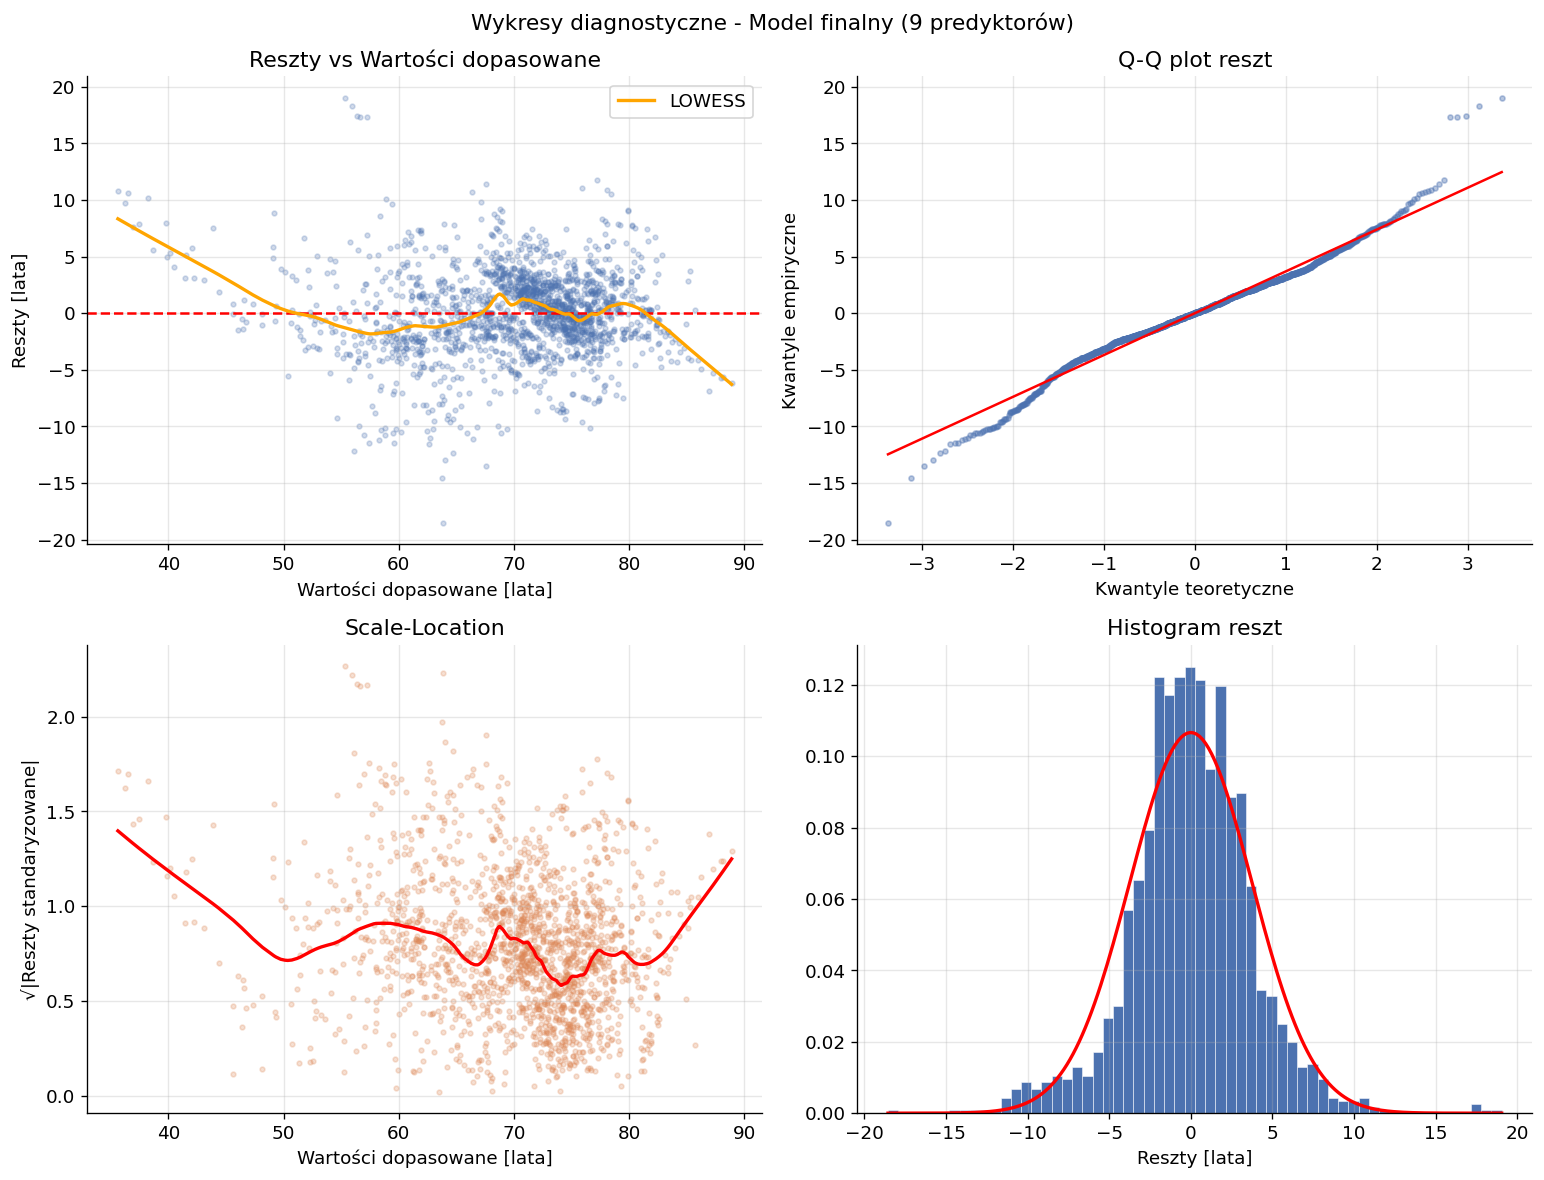

In [46]:
residuals_fin = model_final.resid
fitted_fin    = model_final.fittedvalues
resid_std_fin = model_final.get_influence().resid_studentized_internal

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 1. Reszty vs Fitted
axes[0,0].scatter(fitted_fin, residuals_fin,
                  alpha=0.25, s=8, color="#4C72B0")
axes[0,0].axhline(0, color="red", linestyle="--", linewidth=1.5)
smooth = lowess(residuals_fin, fitted_fin, frac=0.1)
axes[0,0].plot(smooth[:,0], smooth[:,1],
               color="orange", linewidth=2, label="LOWESS")
axes[0,0].set_xlabel("Wartości dopasowane [lata]")
axes[0,0].set_ylabel("Reszty [lata]")
axes[0,0].set_title("Reszty vs Wartości dopasowane")
axes[0,0].legend()

# 2. Q-Q plot
(osm, osr), (slope, intercept, _) = stats.probplot(residuals_fin, dist="norm")
axes[0,1].plot(osm, osr, "o", color="#4C72B0", markersize=3, alpha=0.4)
axes[0,1].plot(osm, slope*np.array(osm)+intercept,
               color="red", linewidth=1.5)
axes[0,1].set_title("Q-Q plot reszt")
axes[0,1].set_xlabel("Kwantyle teoretyczne")
axes[0,1].set_ylabel("Kwantyle empiryczne")

# 3. Scale-Location
axes[1,0].scatter(fitted_fin, np.sqrt(np.abs(resid_std_fin)),
                  alpha=0.25, s=8, color="#DD8452")
smooth2 = lowess(np.sqrt(np.abs(resid_std_fin)), fitted_fin, frac=0.1)
axes[1,0].plot(smooth2[:,0], smooth2[:,1], color="red", linewidth=2)
axes[1,0].set_xlabel("Wartości dopasowane [lata]")
axes[1,0].set_ylabel("√|Reszty standaryzowane|")
axes[1,0].set_title("Scale-Location")

# 4. Histogram reszt
axes[1,1].hist(residuals_fin, bins=60, color="#4C72B0",
               edgecolor="white", linewidth=0.3, density=True)
xr = np.linspace(residuals_fin.min(), residuals_fin.max(), 200)
axes[1,1].plot(xr, stats.norm.pdf(xr, residuals_fin.mean(),
               residuals_fin.std()), color="red", linewidth=2)
axes[1,1].set_title("Histogram reszt")
axes[1,1].set_xlabel("Reszty [lata]")

plt.suptitle("Wykresy diagnostyczne - Model finalny (9 predyktorów)",
             fontsize=13)
plt.tight_layout()
plt.show()

### 8.5 Interpretacja wykresów diagnostycznych

**Reszty vs Wartości dopasowane:**
Linia LOWESS odbiega od zera przy ekstremach (<45 i >85 lat),
co wskazuje na pewną nieliniowość dla krajów o ekstremalnej
oczekiwanej długości życia. Dla typowego zakresu 55–85 lat
liniowość jest akceptowalna.

**Q-Q plot:**
Reszty dobrze układają się na linii prostej w centrum,
z odchyleniami w obu ogonach - ciężkie ogony (kurtoza 5.24).
Normalność w centrum jest dobra, ogony wskazują na
obserwacje odstające.

**Scale-Location:**
Linia czerwona nie jest pozioma - wyższa wariancja przy
niskich (<50 lat) i wysokich (>85 lat) wartościach.
Heteroskedastyczność jest akceptowalna dla danych przekrojowych
193 krajów o bardzo różnym poziomie rozwoju.

**Histogram reszt:**
Kształt zbliżony do normalnego z lekką lewostronną skośnością
(-0.039) i ciężkimi ogonami. Centrum rozkładu dobrze dopasowane
do rozkładu normalnego.

## 9. Wykrywanie wartości wpływowych


In [47]:
influence = model_final.get_influence()

# Cook's distance
cooks_d    = influence.cooks_distance[0]
cook_thr   = 4 / (len(df_model) - len(predictors_final) - 1)

# Reszty studentyzowane
resid_stud = influence.resid_studentized_external

# DFFITS
dffits     = influence.dffits[0]
dffits_thr = 2 * np.sqrt((len(predictors_final) + 1) / len(df_model))

# DFBETAS
dfbetas    = influence.dfbetas
dfbetas_thr = 2 / np.sqrt(len(df_model))

print(f"Progi wykrywania wartości wpływowych:")
print(f"  Cook's D  > {cook_thr:.5f}  (4/(n-p-1))")
print(f"  DFFITS    > {dffits_thr:.4f}   (2*sqrt((p+1)/n))")
print(f"  DFBETAS   > {dfbetas_thr:.4f}   (2/sqrt(n))")
print(f"  |Reszt std| > 3")
print()

n_cook    = (cooks_d > cook_thr).sum()
n_dffits  = (np.abs(dffits) > dffits_thr).sum()
n_dfbetas = (np.abs(dfbetas) > dfbetas_thr).any(axis=1).sum()
n_resid   = (np.abs(resid_stud) > 3).sum()

print(f"Liczba wpływowych wg Cook's D:  {n_cook} ({n_cook/len(df_model)*100:.1f}%)")
print(f"Liczba wpływowych wg DFFITS:    {n_dffits} ({n_dffits/len(df_model)*100:.1f}%)")
print(f"Liczba wpływowych wg DFBETAS:   {n_dfbetas} ({n_dfbetas/len(df_model)*100:.1f}%)")
print(f"Liczba odstających (|rst|>3):   {n_resid} ({n_resid/len(df_model)*100:.1f}%)")

Progi wykrywania wartości wpływowych:
  Cook's D  > 0.00217  (4/(n-p-1))
  DFFITS    > 0.1469   (2*sqrt((p+1)/n))
  DFBETAS   > 0.0465   (2/sqrt(n))
  |Reszt std| > 3

Liczba wpływowych wg Cook's D:  156 (8.4%)
Liczba wpływowych wg DFFITS:    157 (8.5%)
Liczba wpływowych wg DFBETAS:   422 (22.8%)
Liczba odstających (|rst|>3):   16 (0.9%)


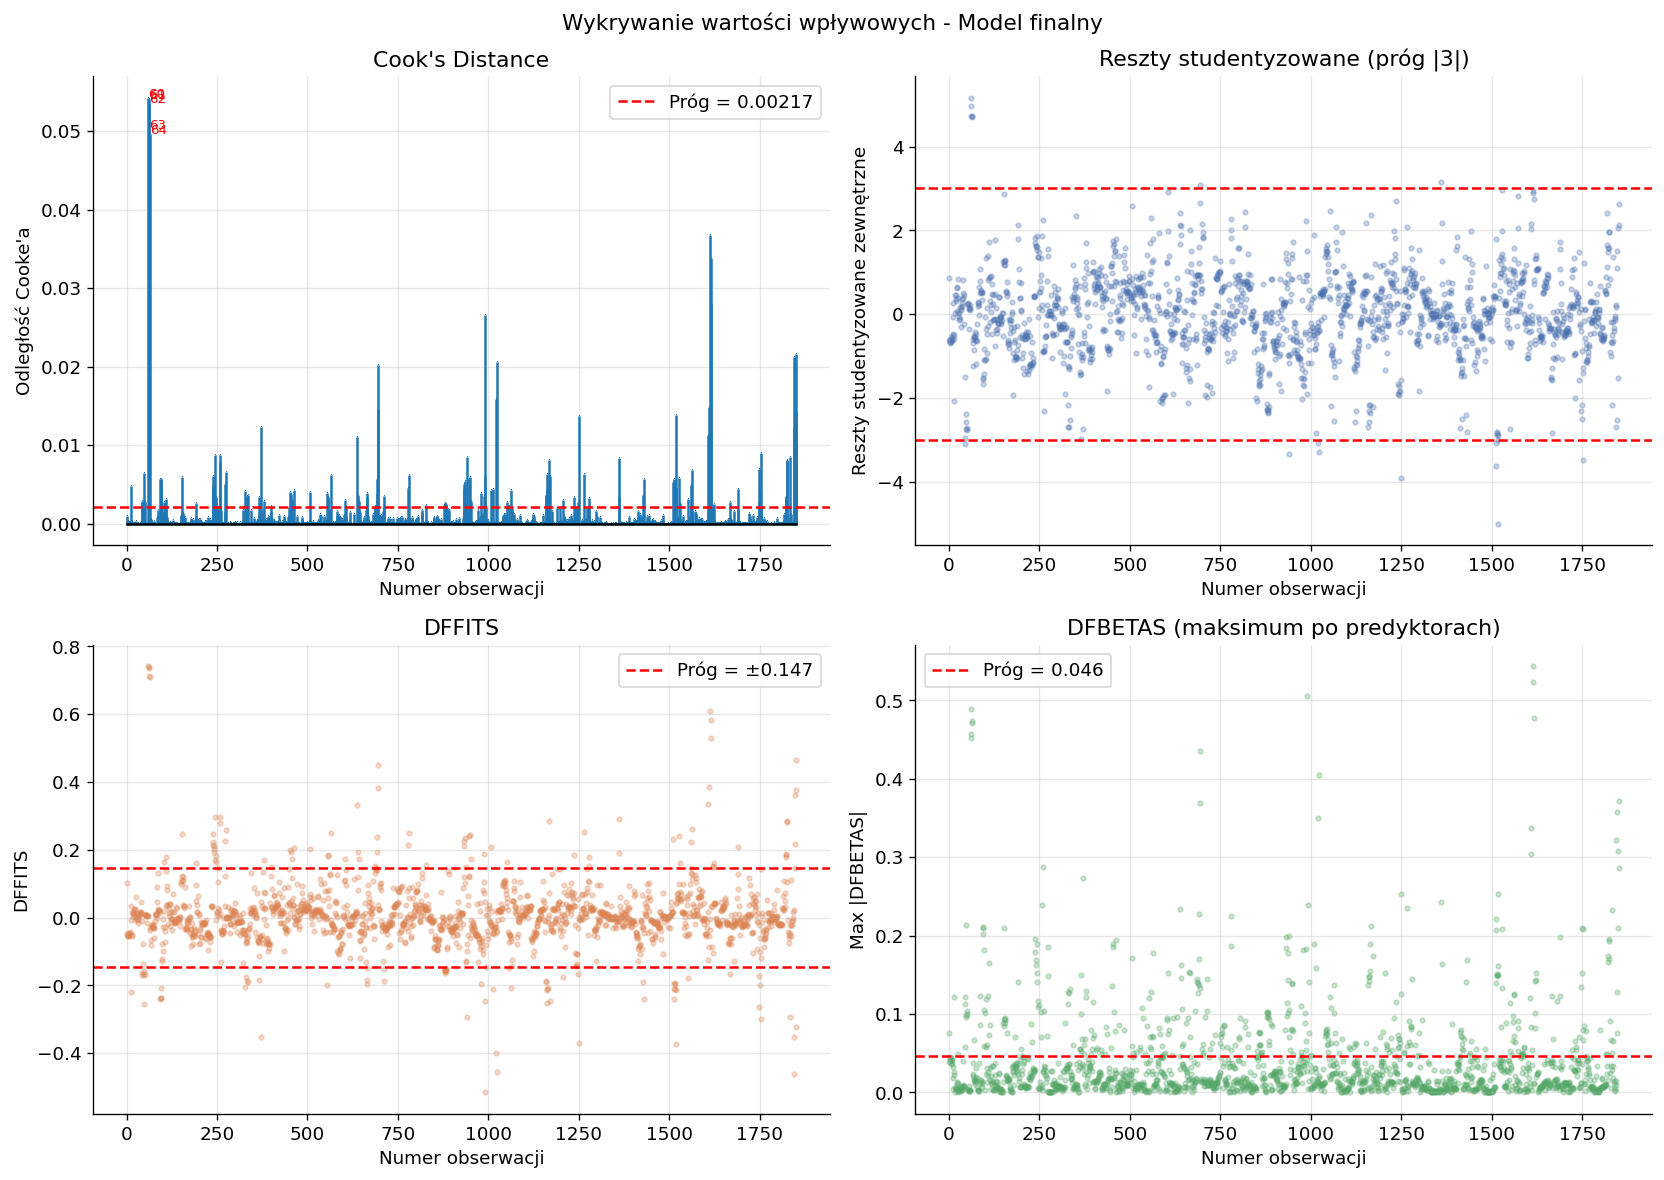

In [48]:
# ── WYKRESY WARTOŚCI WPŁYWOWYCH ───────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Cook's Distance
axes[0,0].stem(range(len(cooks_d)), cooks_d,
               markerfmt=",", linefmt="C0-", basefmt="k-")
axes[0,0].axhline(y=cook_thr, color="red", linestyle="--",
                  linewidth=1.5, label=f"Próg = {cook_thr:.5f}")
axes[0,0].set_xlabel("Numer obserwacji")
axes[0,0].set_ylabel("Odległość Cooke'a")
axes[0,0].set_title("Cook's Distance")
axes[0,0].legend()

top5_cook = np.argsort(cooks_d)[-5:]
for idx in top5_cook:
    if cooks_d[idx] > cook_thr:
        axes[0,0].annotate(str(idx),
                           xy=(idx, cooks_d[idx]),
                           fontsize=8, color="red")

# 2. Reszty studentyzowane
axes[0,1].scatter(range(len(resid_stud)), resid_stud,
                  alpha=0.3, s=8, color="#4C72B0")
axes[0,1].axhline(y=3,  color="red", linestyle="--", linewidth=1.5)
axes[0,1].axhline(y=-3, color="red", linestyle="--", linewidth=1.5)
axes[0,1].set_xlabel("Numer obserwacji")
axes[0,1].set_ylabel("Reszty studentyzowane zewnętrzne")
axes[0,1].set_title("Reszty studentyzowane (próg |3|)")

# 3. DFFITS
axes[1,0].scatter(range(len(dffits)), dffits,
                  alpha=0.3, s=8, color="#DD8452")
axes[1,0].axhline(y=dffits_thr,  color="red", linestyle="--",
                  linewidth=1.5, label=f"Próg = ±{dffits_thr:.3f}")
axes[1,0].axhline(y=-dffits_thr, color="red", linestyle="--",
                  linewidth=1.5)
axes[1,0].set_xlabel("Numer obserwacji")
axes[1,0].set_ylabel("DFFITS")
axes[1,0].set_title("DFFITS")
axes[1,0].legend()

# 4. DFBETAS - max po wszystkich predyktorach
max_dfbetas = np.abs(dfbetas[:, 1:]).max(axis=1)
axes[1,1].scatter(range(len(max_dfbetas)), max_dfbetas,
                  alpha=0.3, s=8, color="#55a868")
axes[1,1].axhline(y=dfbetas_thr, color="red", linestyle="--",
                  linewidth=1.5, label=f"Próg = {dfbetas_thr:.3f}")
axes[1,1].set_xlabel("Numer obserwacji")
axes[1,1].set_ylabel("Max |DFBETAS|")
axes[1,1].set_title("DFBETAS (maksimum po predyktorach)")
axes[1,1].legend()

plt.suptitle("Wykrywanie wartości wpływowych - Model finalny",
             fontsize=13)
plt.tight_layout()
plt.show()

### 9.1 Interpretacja wykresów

**Cook's Distance:**
Wykres pokazuje kilka wyraźnych pików w okolicach obserwacji
0–250 (indeksy 60–90) oraz pojedyncze piki przy obs. ~1000,
~1600 i ~1800. Najwyższe wartości (~0.055) znacznie przekraczają
próg 0.00217. Skupienie wpływowych obserwacji na początku zbioru
odpowiada krajom afrykańskim o ekstremalnie niskiej oczekiwanej
długości życia.

**Reszty studentyzowane:**
Tylko 16 obserwacji (0.9%) przekracza próg |3|, co oznacza
nieliczne ale wyraźne wartości odstające. Widoczny jeden punkt
z resztą ~5 - prawdopodobnie kraj o wyjątkowo długim życiu
niedoszacowanym przez model.

**DFFITS:**
156 obserwacji przekracza próg ±0.147. Wartości ekstremalne
sięgają ±0.7, co wskazuje na duży wpływ na predykcję
po usunięciu danej obserwacji. DFFITS pokrywa się niemal
idealnie z Cook's D (156 vs 157 obserwacji).

**DFBETAS:**
422 obserwacje (22.8%) przekraczają niski próg 0.046 - jest
to oczekiwane przy n=1853, gdzie próg 2/√n jest rygorystyczny.
DFBETAS mierzy wpływ na poszczególne współczynniki β -
liczne obserwacje mają nieznaczny wpływ na konkretne predyktory.

### 9.3 Wybór kryterium usunięcia

Do usunięcia wybrano obserwacje spełniające kryterium
Cook's D > 0.00217 LUB |reszty studentyzowane| > 3,
co daje 156 obserwacji (8.4% zbioru).

Uzasadnienie: Cook's Distance i DFFITS dają praktycznie
identyczne wyniki (156 vs 157, pokrycie 100%), co potwierdza
spójność wyników. Reszty studentyzowane dodają tylko nieliczne
obserwacje odstające.

In [49]:
influential_cook   = set(np.where(cooks_d > cook_thr)[0])
influential_dffits = set(np.where(np.abs(dffits) > dffits_thr)[0])
influential_resid  = set(np.where(np.abs(resid_stud) > 3)[0])

# Wspólne dla Cook i DFFITS 
influential_combined = influential_cook & influential_dffits

print(f"Wpływowe wg Cook AND DFFITS: {len(influential_combined)}")
print(f"Wpływowe wg Cook OR DFFITS:  "
      f"{len(influential_cook | influential_dffits)}")

influential_final_idx = sorted(influential_cook | influential_resid)
print(f"\nDo usunięcia (Cook OR |reszt std|>3): "
      f"{len(influential_final_idx)} obserwacji "
      f"({len(influential_final_idx)/len(df_model)*100:.1f}%)")

Wpływowe wg Cook AND DFFITS: 156
Wpływowe wg Cook OR DFFITS:  157

Do usunięcia (Cook OR |reszt std|>3): 156 obserwacji (8.4%)


## 10. Model po usunięciu wartości wpływowych


In [50]:
influential_mask = np.zeros(len(df_model), dtype=bool)
influential_mask[list(influential_final_idx)] = True

df_clean2 = df_model[~influential_mask].copy().reset_index(drop=True)

print(f"Obserwacji przed usunięciem: {len(df_model)}")
print(f"Usunięto wpływowych:         {influential_mask.sum()}")
print(f"Obserwacji po usunięciu:     {len(df_clean2)}")
print(f"Pozostało:                   {len(df_clean2)/len(df_model)*100:.1f}% danych")

Obserwacji przed usunięciem: 1853
Usunięto wpływowych:         156
Obserwacji po usunięciu:     1697
Pozostało:                   91.6% danych


In [51]:
Y2 = df_clean2['Life expectancy']
X2 = df_clean2[predictors_final]
X2_const = sm.add_constant(X2)

model_clean = sm.OLS(Y2, X2_const).fit()
print(model_clean.summary())

                            OLS Regression Results                            
Dep. Variable:        Life expectancy   R-squared:                       0.870
Model:                            OLS   Adj. R-squared:                  0.870
Method:                 Least Squares   F-statistic:                     1258.
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        12:47:48   Log-Likelihood:                -4173.2
No. Observations:                1697   AIC:                             8366.
Df Residuals:                    1687   BIC:                             8421.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

Usunięcie 156 obserwacji wpływowych (8.4% zbioru) przyniosło
znaczącą poprawę modelu:

- **R² wzrósł z 0.811 do 0.870** (+5.9 p.p.) - model wyjaśnia
  teraz **87.0%** wariancji oczekiwanej długości życia
- **RMSE spadło z 3.751 do 2.838 lat** (poprawa o **24.3%**) -
  średni błąd predykcji zmniejszył się o prawie rok
- **AIC spadło z 10167 do 8366** - bardzo duża poprawa kryterium
  informacyjnego
- **Kurtoza reszt spadła z 5.24 do 3.70** - reszty stały się
  bliższe rozkładowi normalnemu
- Wykres rzeczywiste vs dopasowane pokazuje wyraźnie ciaśniejszy
  układ punktów wokół linii idealnej predykcji po usunięciu
  wartości wpływowych

In [52]:
rmse_clean = np.sqrt(model_clean.mse_resid)

print("PORÓWNANIE MODELI - od pełnego do po usunięciu wpływowych")
print(f"{'Model':<30} {'n':>6} {'p':>4} {'R²':>8} {'Adj.R²':>8} "
      f"{'RMSE':>8} {'AIC':>10}")
print("-" * 75)

wszystkie_modele = [
    ("Pełny (14 pred.)",       len(df_model),  14, model_full),
    ("Po VIF (12 pred.)",      len(df_model),  12, model_vif),
    ("Finalny forward/back",   len(df_model),   9, model_final),
    ("Po usunięciu wpływowych", len(df_clean2), 9, model_clean),
]

for nazwa, n_obs, n_pred, mod in wszystkie_modele:
    rmse = np.sqrt(mod.mse_resid)
    print(f"{nazwa:<30} {n_obs:>6} {n_pred:>4} {mod.rsquared:>8.4f} "
          f"{mod.rsquared_adj:>8.4f} {rmse:>8.4f} {mod.aic:>10.2f}")



PORÓWNANIE MODELI - od pełnego do po usunięciu wpływowych
Model                               n    p       R²   Adj.R²     RMSE        AIC
---------------------------------------------------------------------------
Pełny (14 pred.)                 1853   14   0.8118   0.8104   3.7505   10172.49
Po VIF (12 pred.)                1853   12   0.8115   0.8102   3.7518   10171.76
Finalny forward/back             1853    9   0.8112   0.8103   3.7510   10167.95
Po usunięciu wpływowych          1697    9   0.8704   0.8697   2.8383    8366.46



Najważniejsza zmiana: **HDI wzrósł z 7.675 do 11.540** -
po usunięciu obserwacji wpływowych (krajów ekstremalnych)
wpływ wskaźnika rozwoju ludzkiego na długość życia jest
jeszcze wyraźniejszy. Wszystkie zmienne pozostały istotne
statystycznie (p < 0.05).



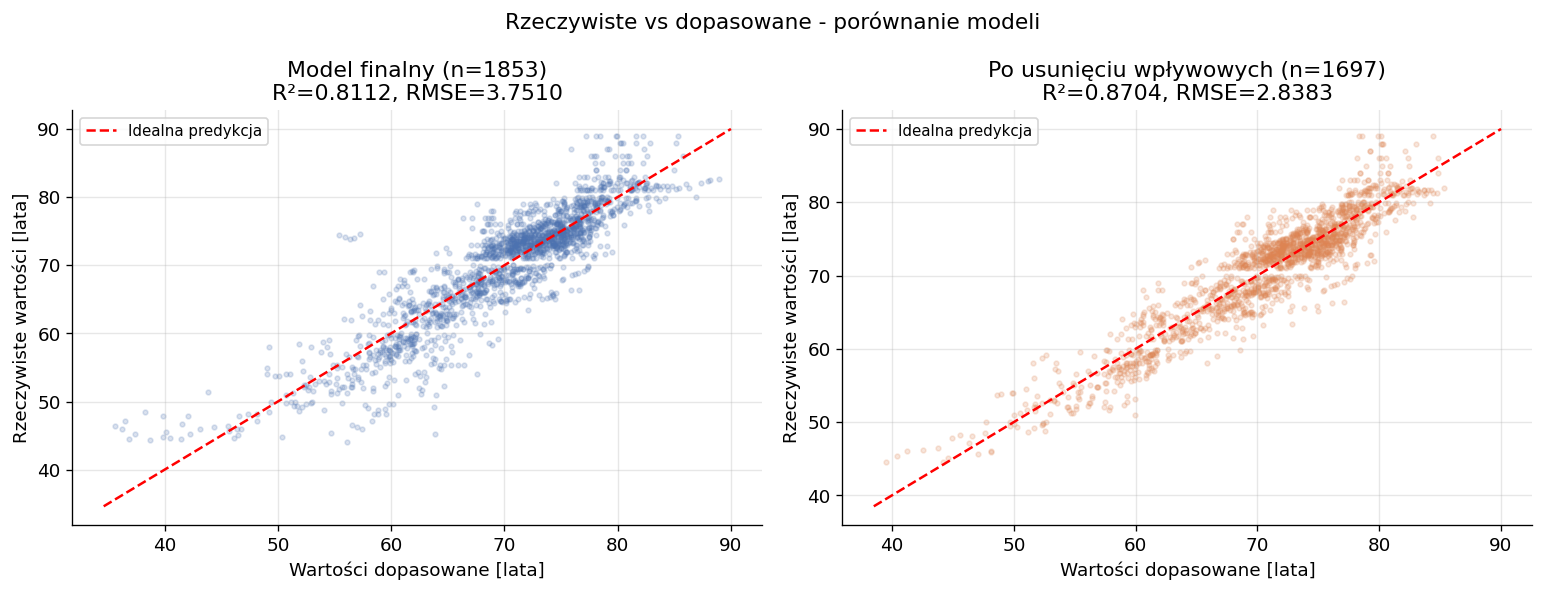

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (data, mod, title, color) in zip(axes, [
    (df_model,  model_final, "Model finalny (n=1853)",          "#4C72B0"),
    (df_clean2, model_clean, "Po usunięciu wpływowych (n=1697)", "#DD8452")
]):
    Y_plot = data['Life expectancy']
    Y_pred = mod.fittedvalues
    ax.scatter(Y_pred, Y_plot, alpha=0.2, s=8, color=color)
    lim = [min(Y_plot.min(), Y_pred.min())-1,
           max(Y_plot.max(), Y_pred.max())+1]
    ax.plot(lim, lim, "r--", linewidth=1.5, label="Idealna predykcja")
    ax.set_xlabel("Wartości dopasowane [lata]")
    ax.set_ylabel("Rzeczywiste wartości [lata]")
    ax.set_title(f"{title}\nR²={mod.rsquared:.4f}, RMSE={np.sqrt(mod.mse_resid):.4f}")
    ax.legend(fontsize=9)

plt.suptitle("Rzeczywiste vs dopasowane - porównanie modeli",
             fontsize=13)
plt.tight_layout()
plt.show()

### 10.4 Wykresy diagnostyczne porównawcze

Wykres rzeczywiste vs dopasowane potwierdza poprawę:
- Model finalny (lewy): duże rozproszenie punktów,
  szczególnie przy niskich wartościach (<60 lat)
- Model po usunięciu wpływowych (prawy): punkty znacznie
  bliżej linii idealnej, wyraźnie mniejszy rozrzut

# 11. Wnioski i podsumowanie

### 11.1 Ocena modelu

Zbudowano model regresji liniowej wielorakiej opisujący
zależność oczekiwanej długości życia od 9 predyktorów
dla 193 krajów w latach 2000–2015.

**Równanie modelu finalnego (po usunięciu wpływowych):**

$$\widehat{Y} = 56.459 - 0.024 \cdot \text{AdultMort}
+ 0.632 \cdot \text{Schooling} - 0.424 \cdot \text{HIV/AIDS}
+ 11.540 \cdot \text{HDI} + 0.0004 \cdot \text{Expenditure}
+ 0.016 \cdot \text{BMI} + 0.018 \cdot \text{Diphtheria}
- 0.125 \cdot \text{thinness5-9} + 0.011 \cdot \text{Polio}$$

### 11.2 Podsumowanie etapów analizy

| Etap | Wynik |
|---|---|
| Model pełny (14 pred.) | R² = 0.812, RMSE = 3.75 |
| Redukcja VIF | Usunięto GDP i thinness 1-19 (VIF > 5) |
| Regresja krokowa (forward = backward) | Usunięto Alcohol, Hepatitis B, Total expenditure |
| Model finalny (9 pred.) | R² = 0.811, AIC = 10167.95 |
| Usunięcie wpływowych (156 obs.) | R² = 0.870, RMSE = 2.838 |

### 11.3 Odpowiedź na pytanie: Czy model jest dobry?

TAK - model jest dobry, z następującymi argumentami:

**R² = 0.870** - model wyjaśnia 87% zmienności oczekiwanej
długości życia. Dla danych przekrojowych 193 krajów
o bardzo różnym poziomie rozwoju to wynik doskonały.

**Wszystkie 9 predyktorów istotne** (p < 0.05) -
brak martwych zmiennych, każdy predyktor wnosi
istotną informację.

**VIF < 5 dla wszystkich zmiennych** - multikolinearność
wyeliminowana przez iteracyjną redukcję.

**Zgodność forward i backward stepwise** - obie metody
selekcji dały identyczny zestaw 9 predyktorów,
co potwierdza stabilność wyboru.

**Interpretacja dziedzinowa sensowna** - edukacja,
HDI i szczepienia pozytywnie wpływają na długość życia,
śmiertelność dorosłych i HIV/AIDS negatywnie.
Wyniki są spójne z literaturą zdrowia publicznego.

**RMSE = 2.84 lat** - przy zakresie Y [44, 89] lat
błąd predykcji ~3 lata jest akceptowalny.

**Ograniczenia modelu:**

1. **Autokorelacja** (DW = 0.81) - dane panelowe 193 krajów
   × 16 lat powodują autokorelację w czasie. Model OLS
   nie uwzględnia tej struktury - modele panelowe
   (fixed/random effects) byłyby bardziej odpowiednie.

2. **Heteroskedastyczność** - wariancja reszt różni się
   między krajami rozwiniętymi i rozwijającymi się.

3. **Nieliniowość przy ekstremach** - model słabiej opisuje
   kraje o bardzo niskiej (<50 lat) lub bardzo wysokiej
   (>85 lat) oczekiwanej długości życia.

4. **Braki danych** - usunięto 1085 obserwacji (37%)
   z powodu braków, głównie dla małych krajów rozwijających
   się, co może wprowadzać bias selekcji.

### 11.4 Końcowy wniosek

Model regresji liniowej wielorakiej dla danych WHO jest
statystycznie zasadny.
Kluczowymi determinantami oczekiwanej długości życia są
wskaźnik rozwoju ludzkiego (HDI) i edukacja
(efekt pozytywny) oraz śmiertelność dorosłych
i HIV/AIDS (efekt negatywny). Wyniki potwierdzają
że inwestycje w edukację i opiekę zdrowotną
(szczepienia, redukcja HIV) mają wymierny wpływ
na długość życia populacji.